# PRCP-1010 · Insurance Claim Prediction

**Domain:** Finance / Insurance  **Data:** `train.csv` – 595,212 customers, 57 anonymised features + `id` + `target`

| Deliverable | Section |
|---|---|
| Task 1 – predictive model: which customer is likely to claim / respond | 4 – 10 |
| Task 2 – suggestions to the insurance marketing team | 12 |
| Model comparison report + best model for production | 7, 11 |
| Report on challenges faced (technique + reason) | 13 |
| EDA (the statement says it may be skipped; it is done here because it drives the modelling decisions) | 2 – 3 |

**Note on the wording of the task.** The statement asks for the customer who "will buy the product", but the data description says the goal is to predict **insurance claims**. The label `target` is therefore treated as *"customer filed a claim (1) / did not (0)"*, i.e. a **risk score**. Section 12 turns the risk score into marketing and underwriting suggestions. Because the 57 features are anonymised, their real meaning cannot be checked.

## Design of this notebook (and why)
1. **Split first, explore after.** Stratified **train 60 % / validation 20 % / test 20 %** *before* any exploration. EDA and every fitted step use the training part only.
2. **Strict roles:** train → model comparison and tuning (cross-validation inside it); **validation → decision threshold, calibration, feature importance**; **test → touched once**, for the final report.
3. **One `Pipeline`** holds every fitted step (imputation, scaling, encoding, model). Only stateless, row-wise feature construction is done by hand.
4. **Metric choice for a 3.6 % positive rate:** ROC-AUC (equivalently the normalised **Gini = 2·AUC − 1**), PR-AUC, lift and gains. **Accuracy is meaningless here** (always answering "no" is 96.4 % accurate) and is reported only to prove that point.
5. **Comparable tuning for every serious model** (same folds, metric and search budget), on a stratified 80,000-row sample for speed; the final model is then refitted on the **full** training part. A learning curve shows what the extra data buys.
6. **Evidence-based feature decisions** (the 20 `ps_calc_*` features and two engineered count features are kept or dropped by a rule fixed in advance, using cross-validation only).
7. **One final model** is used for evaluation, interpretation and recommendations; uncertainty is shown with bootstrap intervals, calibration and subgroup checks.

**Requirements:** Python ≥ 3.8, `pandas`, `numpy`, `scipy`, `scikit-learn` (≥ 1.1), `xgboost`, `matplotlib`, `seaborn`. Put `train.csv` next to the notebook. Run top to bottom; results are reproducible (`random_state = 42`). The notebook uses all CPU cores where it can; on a single core a full run takes roughly 10 – 20 minutes.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silences a harmless joblib core-count warning on some Windows PCs
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import loguniform, uniform

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score, accuracy_score, brier_score_loss,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})
RS = 42
pd.set_option("display.max_columns", 60, "display.width", 170)

## 1. Load the data

In [2]:
CANDIDATES = ["train.csv", "Data/train.csv", "PRCP-1010-InsClaimPred/train.csv"]
PATH = next((p for p in CANDIDATES if os.path.exists(p)), CANDIDATES[0])
df = pd.read_csv(PATH)
print("File:", PATH, "| shape:", df.shape)
df.head()

File: train.csv | shape: (595212, 59)


,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,ps_ind_09_bin,ps_ind_10_bin,ps_ind_11_bin,ps_ind_12_bin,ps_ind_13_bin,ps_ind_14,ps_ind_15,ps_ind_16_bin,ps_ind_17_bin,ps_ind_18_bin,ps_reg_01,ps_reg_02,ps_reg_03,ps_car_01_cat,ps_car_02_cat,ps_car_03_cat,ps_car_04_cat,ps_car_05_cat,ps_car_06_cat,ps_car_07_cat,ps_car_08_cat,ps_car_09_cat,ps_car_10_cat,ps_car_11_cat,ps_car_11,ps_car_12,ps_car_13,ps_car_14,ps_car_15,ps_calc_01,ps_calc_02,ps_calc_03,ps_calc_04,ps_calc_05,ps_calc_06,ps_calc_07,ps_calc_08,ps_calc_09,ps_calc_10,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,0,0,0,0,0,0,11,0,1,0,0.7,0.2,0.718070,10,1,-1,0,1,4,1,0,0,1,12,2,0.400000,0.883679,0.370810,3.605551,0.6,0.5,0.2,3,1,10,1,10,1,5,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,0,0,0,0,0,0,3,0,0,1,0.8,0.4,0.766078,11,1,-1,0,-1,11,1,1,2,1,19,3,0.316228,0.618817,0.388716,2.449490,0.3,0.1,0.3,2,1,9,5,8,1,7,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,0,0,0,0,0,0,12,1,0,0,0.0,0.0,-1.000000,7,1,-1,0,-1,14,1,1,2,1,60,1,0.316228,0.641586,0.347275,3.316625,0.5,0.7,0.1,2,2,9,1,8,2,7,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,0,0,0,0,0,0,8,1,0,0,0.9,0.2,0.580948,7,1,0,0,1,11,1,1,3,1,104,1,0.374166,0.542949,0.294958,2.000000,0.6,0.9,0.1,2,4,7,1,8,4,2,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,0,0,0,0,0,0,9,1,0,0,0.7,0.6,0.840759,11,1,-1,0,-1,14,1,1,2,1,82,3,0.316070,0.565832,0.365103,2.000000,0.4,0.6,0.0,2,2,6,3,10,2,12,3,1,1,3,0,0,0,1,1,0


## 2. Data understanding

### 2.1 Structure and feature groups
The names follow a convention: `ind` (individual), `reg` (region), `car` (car), `calc` (calculated); the suffix `_bin` marks binary and `_cat` categorical features; everything else is continuous or ordinal. The value **`-1` means "missing"**.

In [3]:
FEATURES = [c for c in df.columns if c not in ("id", "target")]
bin_cols = [c for c in FEATURES if c.endswith("_bin")]
cat_cols = [c for c in FEATURES if c.endswith("_cat")]
num_cols = [c for c in FEATURES if c not in bin_cols + cat_cols]
groups = pd.DataFrame({g: {"binary": sum(c.startswith("ps_" + g) for c in bin_cols), "categorical": sum(c.startswith("ps_" + g) for c in cat_cols),
                           "continuous / ordinal": sum(c.startswith("ps_" + g) for c in num_cols)} for g in ["ind", "reg", "car", "calc"]}).T
groups["total"] = groups.sum(axis=1); display(groups)
print("Total features:", len(FEATURES), "| dtypes:", df[FEATURES].dtypes.astype(str).value_counts().to_dict())
display(pd.DataFrame({"n_unique": df[FEATURES].nunique(), "min": df[FEATURES].min(), "max": df[FEATURES].max()}).T.round(2))

,binary,categorical,continuous / ordinal,total
ind,11,3,4,18
reg,0,0,3,3
car,0,11,5,16
calc,6,0,14,20


Total features: 57 | dtypes: {'int64': 47, 'float64': 10}


,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,ps_ind_09_bin,ps_ind_10_bin,ps_ind_11_bin,ps_ind_12_bin,ps_ind_13_bin,ps_ind_14,ps_ind_15,ps_ind_16_bin,ps_ind_17_bin,ps_ind_18_bin,ps_reg_01,ps_reg_02,ps_reg_03,ps_car_01_cat,ps_car_02_cat,ps_car_03_cat,ps_car_04_cat,ps_car_05_cat,ps_car_06_cat,ps_car_07_cat,ps_car_08_cat,ps_car_09_cat,ps_car_10_cat,ps_car_11_cat,ps_car_11,ps_car_12,ps_car_13,ps_car_14,ps_car_15,ps_calc_01,ps_calc_02,ps_calc_03,ps_calc_04,ps_calc_05,ps_calc_06,ps_calc_07,ps_calc_08,ps_calc_09,ps_calc_10,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
n_unique,8.0,5.0,12.0,3.0,8.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,5.0,14.0,2.0,2.0,2.0,10.0,19.0,5013.00,13.0,3.0,3.0,10.0,3.0,18.0,3.0,2.0,6.0,3.0,104.0,5.0,184.00,70482.00,850.00,15.00,10.0,10.0,10.0,6.0,7.0,11.0,10.0,11.0,8.0,26.0,20.0,11.0,14.0,24.0,2.0,2.0,2.0,2.0,2.0,2.0
min,0.0,-1.0,0.0,-1.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.00,-1.0,-1.0,-1.0,0.0,-1.0,0.0,-1.0,0.0,-1.0,0.0,1.0,-1.0,-1.00,0.25,-1.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,7.0,4.0,11.0,1.0,6.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,13.0,1.0,1.0,1.0,0.9,1.8,4.04,11.0,1.0,1.0,9.0,1.0,17.0,1.0,1.0,4.0,2.0,104.0,3.0,1.26,3.72,0.64,3.74,0.9,0.9,0.9,5.0,6.0,10.0,9.0,12.0,7.0,25.0,19.0,10.0,13.0,23.0,1.0,1.0,1.0,1.0,1.0,1.0


### 2.2 Identifier, duplicates and the target

In [4]:
print("`id` unique:", df["id"].is_unique, "| NaN cells:", int(df.isna().sum().sum()), "| duplicate rows (ignoring id):", int(df[FEATURES + ["target"]].duplicated().sum()))
print("Target distribution:\n", df["target"].value_counts().rename({0: "no claim", 1: "claim"}).to_frame("n").assign(share=lambda d: (d.n / d.n.sum()).round(4)))
# does the identifier carry information (e.g. an ordering effect)?  -> claim rate by id decile
print("Correlation(id, target) = %.4f" % df["id"].corr(df["target"]))
display(df.groupby(pd.qcut(df["id"], 10, labels=False))["target"].mean().round(4).to_frame("claim rate by id decile").T)

`id` unique: True | NaN cells: 0 | duplicate rows (ignoring id): 0
Target distribution:
                n   share
target                  
no claim  573518  0.9636
claim      21694  0.0364
Correlation(id, target) = -0.0002


id,0,1,2,3,4,5,6,7,8,9
claim rate by id decile,0.0368,0.0368,0.037,0.0351,0.0366,0.0365,0.036,0.0366,0.0365,0.0367


**Decisions:** `id` is only a row label (unique, no relation to the target) and is **dropped**. There are no `NaN`s and no duplicate rows, so nothing is removed. The target is strongly imbalanced (≈ 3.6 % positives).

### 2.3 Missing information (`-1`)
For every affected column: how many rows, and does a *missing* value behave differently from a known one?

In [5]:
rows = []
for c in FEATURES:
    m = df[c] == -1
    if m.any():
        rows.append({"column": c, "type": "cat" if c in cat_cols else ("bin" if c in bin_cols else "num"), "n_missing": int(m.sum()),
                     "pct_missing": round(100 * m.mean(), 2), "claim_rate_if_missing": round(df.loc[m, "target"].mean(), 4),
                     "claim_rate_if_known": round(df.loc[~m, "target"].mean(), 4)})
miss_tbl = pd.DataFrame(rows).set_index("column").sort_values("pct_missing", ascending=False)
display(miss_tbl)
print("Rows with at least one missing value: %.1f %%" % (100 * (df[FEATURES] == -1).any(axis=1).mean()))

,type,n_missing,pct_missing,claim_rate_if_missing,claim_rate_if_known
column,,,,,
ps_car_03_cat,cat,411231,69.09,0.0327,0.0448
ps_car_05_cat,cat,266551,44.78,0.0317,0.0403
ps_reg_03,num,107772,18.11,0.0284,0.0382
ps_car_14,num,42620,7.16,0.0404,0.0361
ps_car_07_cat,cat,11489,1.93,0.0782,0.0356
ps_ind_05_cat,cat,5809,0.98,0.0833,0.0360
ps_car_09_cat,cat,569,0.10,0.0914,0.0364
ps_ind_02_cat,cat,216,0.04,0.1852,0.0364
ps_car_01_cat,cat,107,0.02,0.3178,0.0364


Rows with at least one missing value: 79.0 %


**Findings – missing values (`-1`)**
- `ps_car_03_cat` is missing for **69.1 %** of customers and `ps_car_05_cat` for **44.8 %**; `ps_reg_03` for 18.1 %. **79 % of all customers have at least one missing value**, so dropping rows is out of the question.
- Missingness is informative, and not always in the same direction: when `ps_car_03_cat` is missing the claim rate is 3.3 % (vs 4.5 % when known); but the rarely missing fields flag higher risk – `ps_ind_04_cat` (83 rows) 39.8 %, `ps_car_01_cat` (107) 31.8 %, `ps_ind_02_cat` (216) 18.5 %, `ps_car_09_cat` (569) 9.1 %, `ps_ind_05_cat` (5,809) 8.3 %, `ps_car_07_cat` (11,489) 7.8 %, against an average of 3.6 %. The smallest groups are too small to trust individually, which is another reason to keep `-1` as a category and add missing-indicators instead of imputing silently.

**Decision:** for categorical columns `-1` is kept as **its own category** (missingness can be informative). For continuous columns `-1` becomes `NaN`, is **median-imputed inside the pipeline** and a **missing-indicator** column is added, so the model can still use the fact that the value was missing. Rows are never deleted.

### 2.4 Train / validation / test split — *before* any exploration

In [6]:
X_all, y_all = df[FEATURES], df["target"]
X_tmp, X_test, y_tmp, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=RS)
X_fit, X_val, y_fit, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=RS)
# stratified 80,000-row sample of the TRAINING part, used only for fast comparison / tuning (cross-validation)
X_sub, _, y_sub, _ = train_test_split(X_fit, y_fit, train_size=80000, stratify=y_fit, random_state=RS)
split_tbl = pd.DataFrame({"rows": [len(X_fit), len(X_sub), len(X_val), len(X_test)],
                          "claim rate": [y_fit.mean(), y_sub.mean(), y_val.mean(), y_test.mean()],
                          "used for": ["EDA, final model fit", "model comparison + tuning (cross-validation)",
                                       "decision threshold, calibration, feature importance", "final report ONLY (touched once)"]},
                         index=["train (60 %)", "  of which tuning sample", "validation (20 %)", "test (20 %)"])
display(split_tbl.round(4))
eda = X_fit.copy(); eda["target"] = y_fit

,rows,claim rate,used for
train (60 %),357126,0.0364,"EDA, final model fit"
of which tuning sample,80000,0.0365,model comparison + tuning (cross-validation)
validation (20 %),119043,0.0364,"decision threshold, calibration, feature impor..."
test (20 %),119043,0.0364,final report ONLY (touched once)


## 3. Exploratory data analysis (training part only)

### 3.1 Target

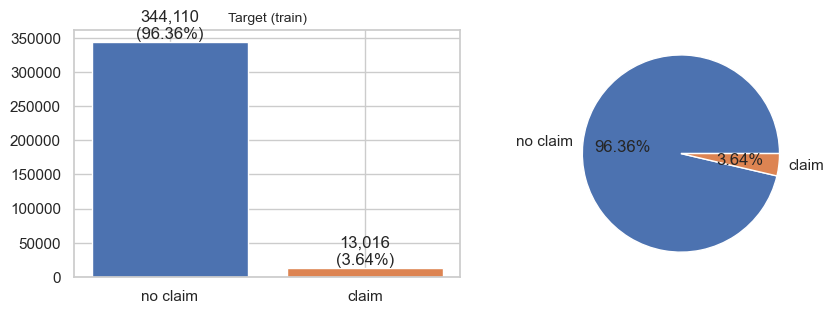

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
vc = eda["target"].map({0: "no claim", 1: "claim"}).value_counts()
ax[0].bar(vc.index, vc.values, color=["#4c72b0", "#dd8452"]); ax[0].set_title("Target (train)")
for i, v in enumerate(vc.values): ax[0].text(i, v, "%s\n(%.2f%%)" % (format(v, ","), 100 * v / len(eda)), ha="center", va="bottom")
ax[1].pie(vc.values, labels=vc.index, autopct="%1.2f%%", colors=["#4c72b0", "#dd8452"]); plt.tight_layout(); plt.show()

**Observation:** only **3.64 %** of customers file a claim (21,694 of 595,212 in total; the training part has the same share) – an imbalance of about **26 : 1**. Always answering "no" would be 96.4 % accurate and completely useless, so accuracy cannot be the yardstick; ranking metrics (ROC-AUC / Gini, PR-AUC) and lift are used instead.

### 3.2 Continuous / ordinal features (all 26): distribution

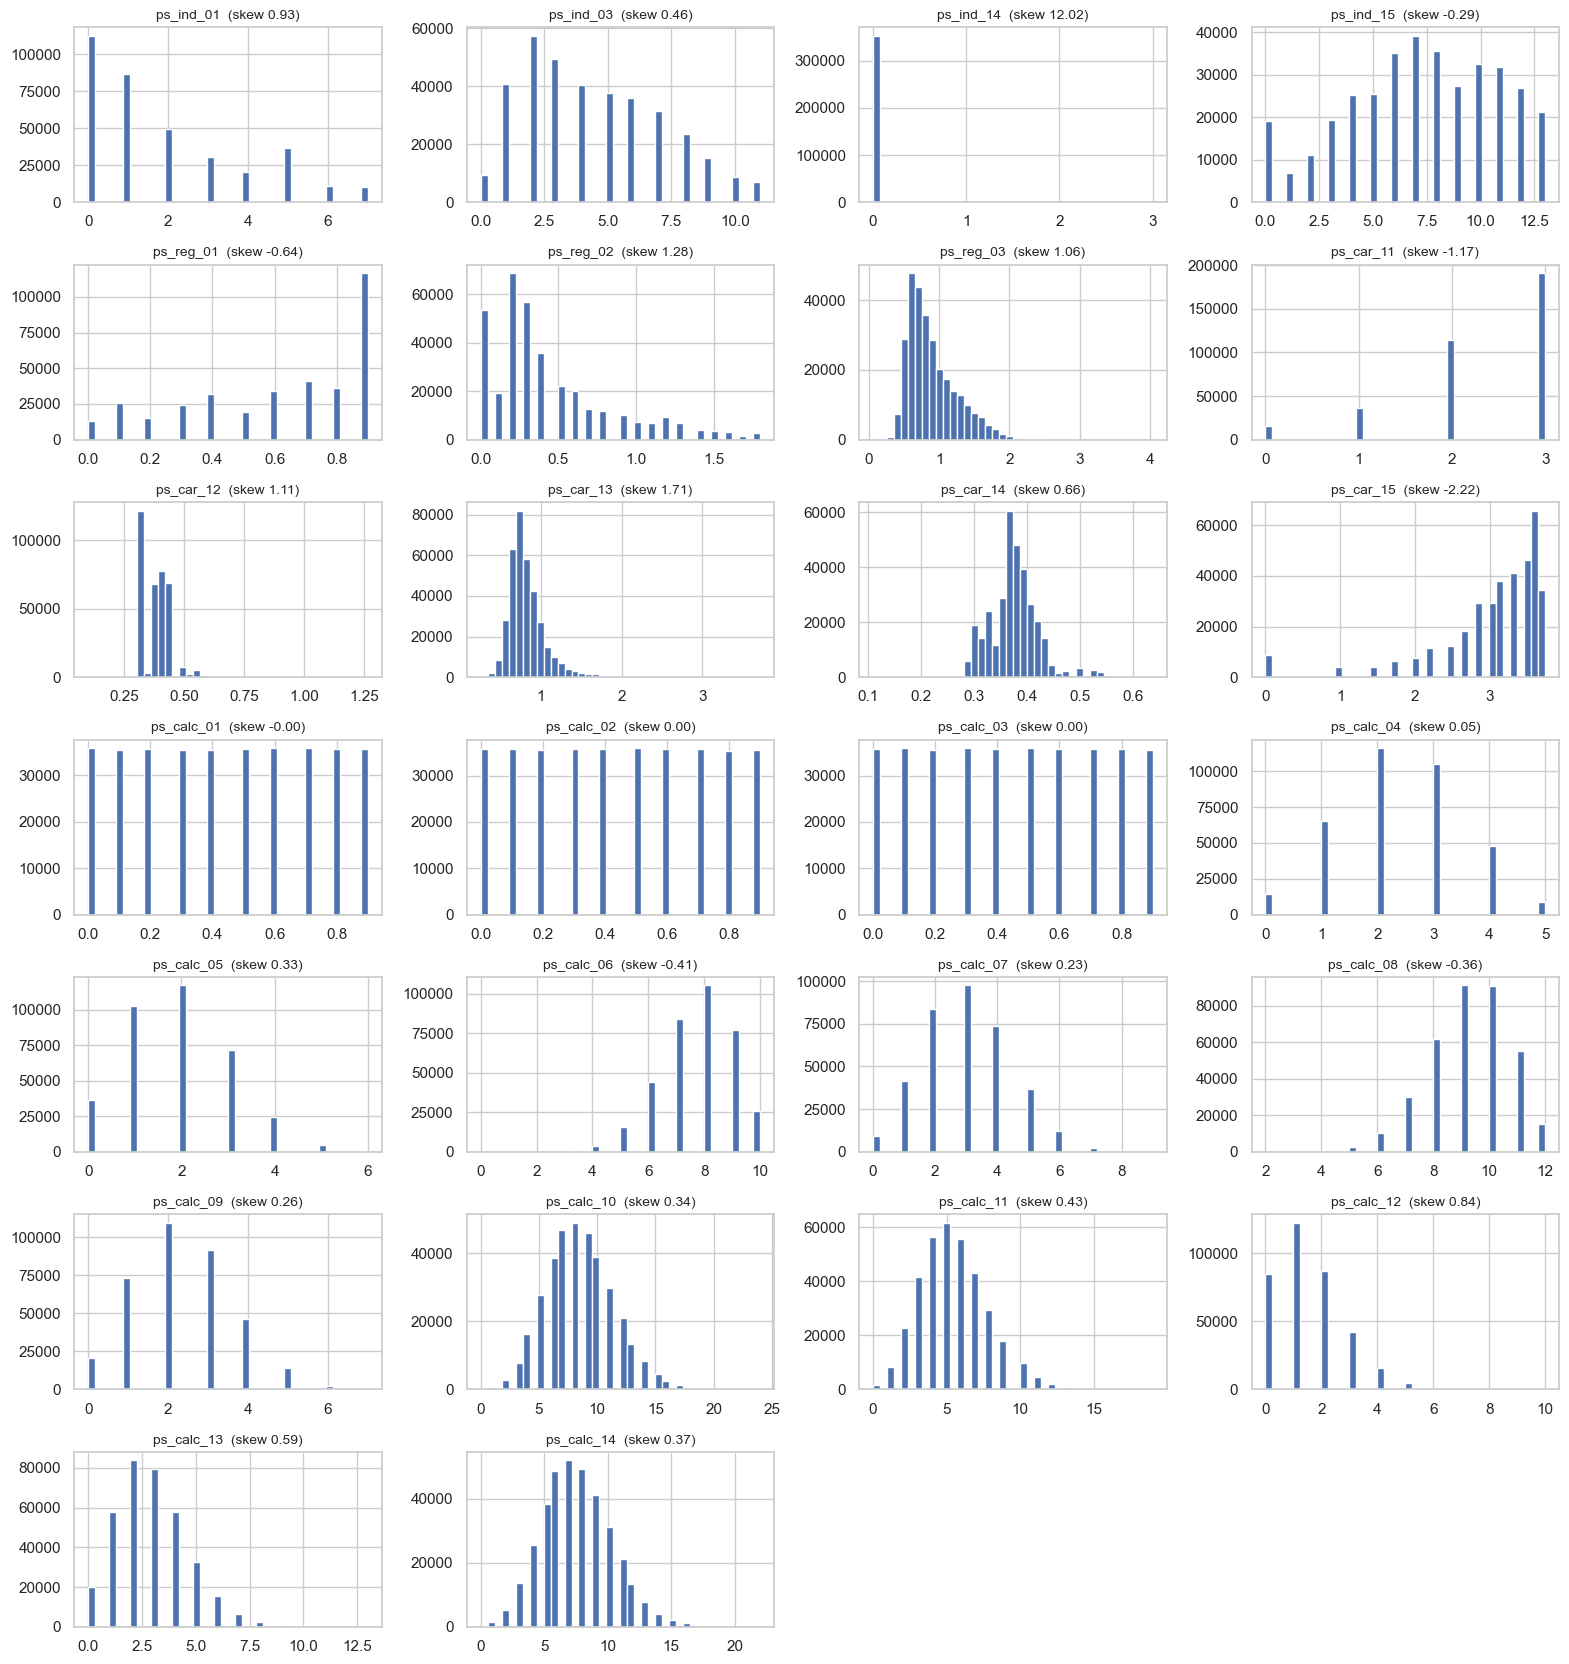

In [8]:
nc = 4; nr = int(np.ceil(len(num_cols) / nc))
fig, axes = plt.subplots(nr, nc, figsize=(16, 2.4 * nr)); axes = axes.ravel()
for ax, c in zip(axes, num_cols):
    s = eda[c].where(eda[c] != -1)
    ax.hist(s.dropna(), bins=40, color="#4c72b0"); ax.set_title("%s  (skew %.2f)" % (c, s.skew()))
for ax in axes[len(num_cols):]: ax.axis("off")
plt.tight_layout(); plt.show()

**Observations (continuous / ordinal features)**
- Most are **discrete ordinal scales**: `ps_ind_01/03/14/15`, `ps_reg_01/02`, `ps_car_11/15` have between 4 and 19 distinct values; only `ps_reg_03` (≈ 4,900 values), `ps_car_12` (170), `ps_car_14` (831) and `ps_car_13` (≈ 57,000) are truly continuous.
- Skew: `ps_car_13` 1.76, `ps_reg_02` / `ps_reg_03` 1.29, `ps_car_12` 1.21 (right-skewed) and `ps_car_15` −2.22 (left-skewed). Skew is harmless for the tree models and is handled by scaling for the linear one.
- The 14 continuous `ps_calc_*` features have only 6 – 25 distinct values and almost no skew (|skew| ≤ 0.84; three are exactly symmetric) – they look like evenly spread, artificially generated numbers rather than real measurements; the next sections test whether they carry any signal.

### 3.3 Binary features (all 17): claim rate by value

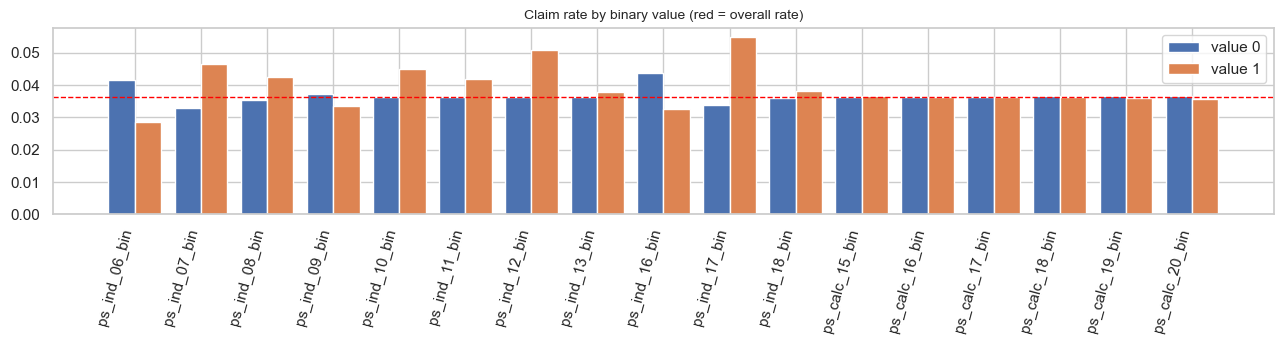

,value 0,value 1,share with value 1
ps_ind_06_bin,0.0415,0.0287,0.3928
ps_ind_07_bin,0.0329,0.0466,0.2569
ps_ind_08_bin,0.0352,0.0426,0.1643
ps_ind_09_bin,0.0371,0.0334,0.1860
ps_ind_10_bin,0.0364,0.0451,0.0004
ps_ind_11_bin,0.0364,0.0417,0.0016
ps_ind_12_bin,0.0363,0.0510,0.0094
ps_ind_13_bin,0.0364,0.0380,0.0009
ps_ind_16_bin,0.0437,0.0327,0.6610
ps_ind_17_bin,0.0339,0.0550,0.1209


In [9]:
g = pd.DataFrame({c: eda.groupby(c)["target"].mean() for c in bin_cols}).T
g.columns = ["value 0", "value 1"]; g["share with value 1"] = [eda[c].mean() for c in g.index]
base = eda["target"].mean()
fig, ax = plt.subplots(figsize=(13, 3.6)); x = np.arange(len(g))
ax.bar(x - .2, g["value 0"], .4, label="value 0"); ax.bar(x + .2, g["value 1"], .4, label="value 1"); ax.axhline(base, color="red", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=75, ha="right"); ax.set_title("Claim rate by binary value (red = overall rate)"); ax.legend(); plt.tight_layout(); plt.show()
display(g.round(4))

**Observations (binary features)**
- Real signal: `ps_ind_17_bin = 1` (12 % of customers) → **5.5 %** vs 3.4 %; `ps_ind_07_bin = 1` 4.7 % vs 3.3 %; `ps_ind_12_bin = 1` (0.9 %) 5.1 %; `ps_ind_06_bin = 1` (39 %) 2.9 % vs 4.2 %; `ps_ind_16_bin = 1` (66 %) 3.3 % vs 4.4 %.
- All six `ps_calc_*_bin` features give 3.6 – 3.7 % **regardless of their value** – no signal.

### 3.4 Categorical features (all 14): claim rate by level
`-1` (missing) is shown as its own level; levels with fewer than 200 customers are omitted from the plots.

          ps_ind_02_cat  ps_ind_04_cat  ps_ind_05_cat  ps_car_01_cat  ps_car_02_cat  ps_car_03_cat  ps_car_04_cat  ps_car_05_cat  ps_car_06_cat  ps_car_07_cat  \
n_levels              5              3              8             13              3              3             10              3             18              3   

          ps_car_08_cat  ps_car_09_cat  ps_car_10_cat  ps_car_11_cat  
n_levels              2              6              3            104  


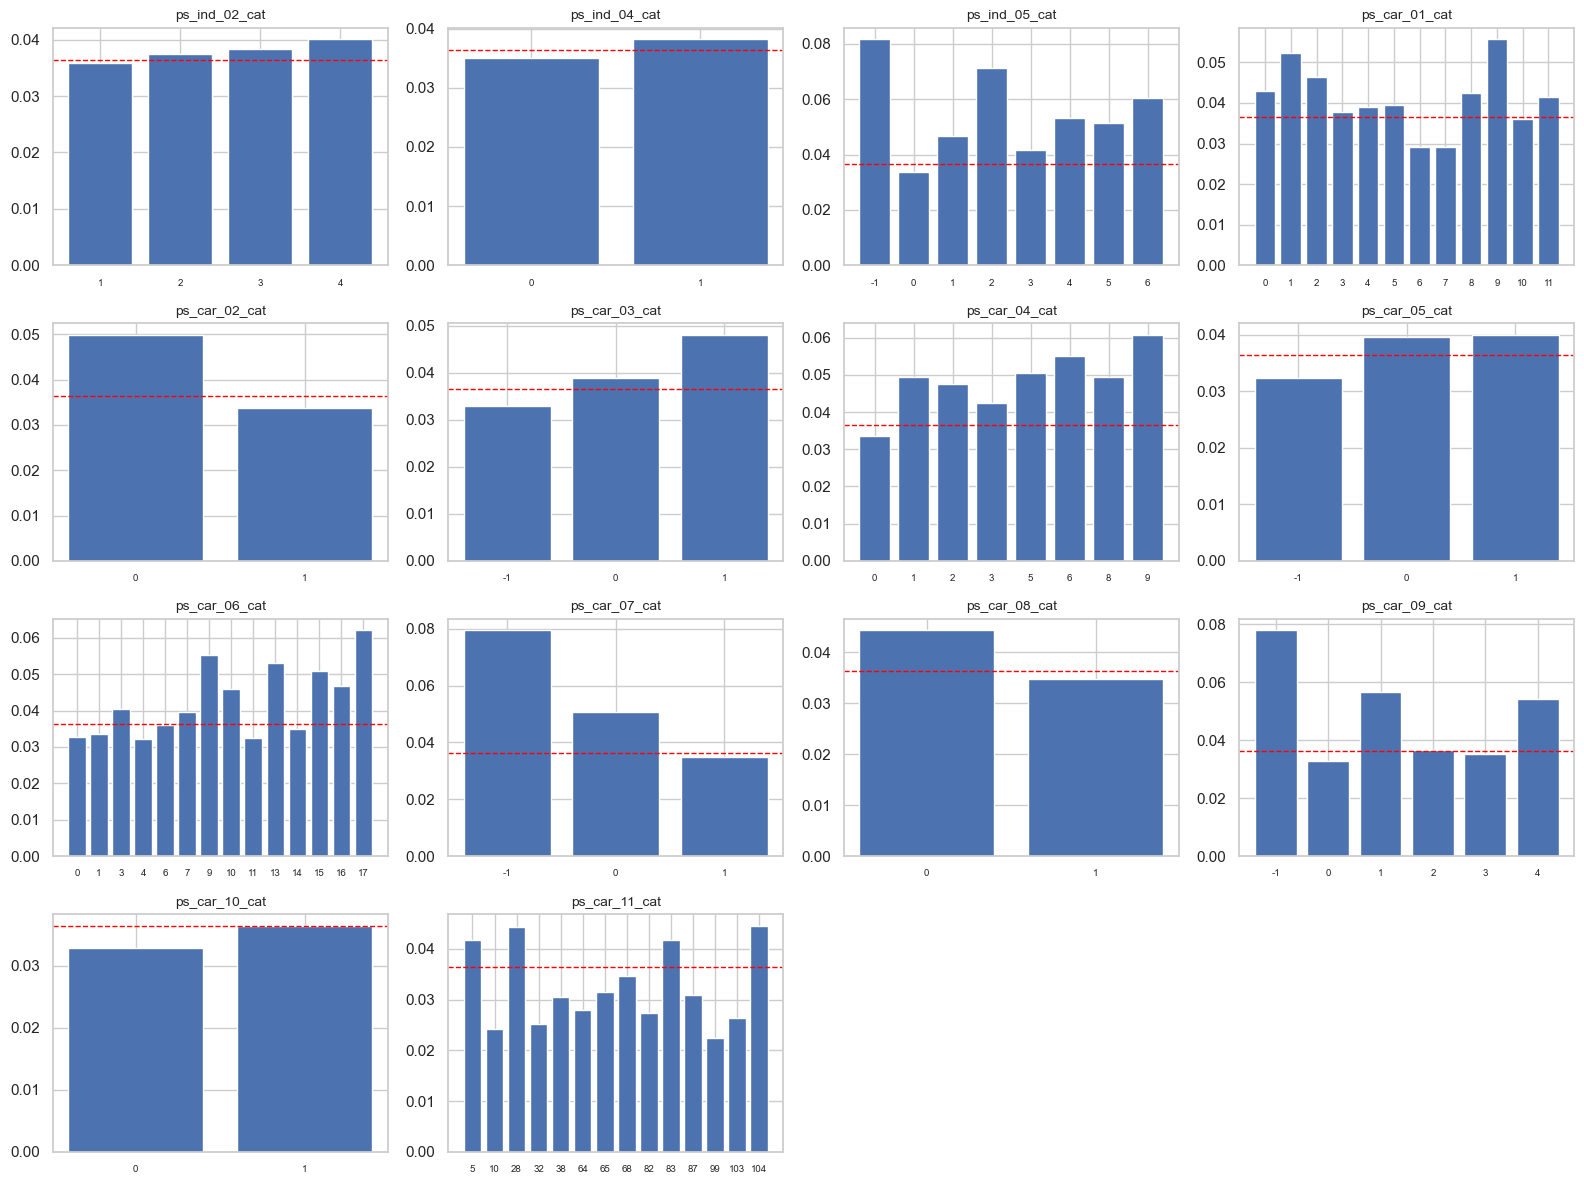

In [10]:
print(eda[cat_cols].nunique().rename("n_levels").to_frame().T)
nc = 4; nr = int(np.ceil(len(cat_cols) / nc))
fig, axes = plt.subplots(nr, nc, figsize=(16, 3.0 * nr)); axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    t = eda.groupby(c)["target"].agg(rate="mean", n="size"); t = t[t.n >= 200]
    if len(t) > 14: t = t.sort_values("n", ascending=False).head(14)
    t = t.sort_index()
    ax.bar(t.index.astype(str), t["rate"], color="#4c72b0"); ax.axhline(base, color="red", ls="--", lw=1); ax.set_title(c); ax.tick_params(axis="x", labelsize=7)
for ax in axes[len(cat_cols):]: ax.axis("off")
plt.tight_layout(); plt.show()

**Observations (categorical features; red line = overall 3.64 %)**
- **`ps_car_11_cat` has 104 levels** with claim rates from 1.5 % to 8.2 % (the largest level, 104, holds 51,112 customers at 4.5 %): a high-cardinality feature that must not be one-hot encoded naively. Other informative features: `ps_car_06_cat` (3.2 – 6.8 %), `ps_car_01_cat` (2.9 – 5.6 %), `ps_car_04_cat` (3.4 – 6.1 %).
- The missing level (`-1`) stands out for `ps_ind_05_cat` (8.2 %), `ps_car_07_cat` (7.9 %) and `ps_car_09_cat` (7.8 %), but is *below* average for `ps_car_03_cat` / `ps_car_05_cat` (≈ 3.2 – 3.3 %).
- `ps_ind_02_cat`, `ps_ind_04_cat`, `ps_car_08_cat` and `ps_car_10_cat` differ by less than 1 percentage point between levels – weak predictors.

### 3.5 Which features carry any signal? (univariate ranking)
Each feature alone is scored by the ROC-AUC of the target against the feature (categorical features use their in-sample claim-rate per level, so those bars are slightly optimistic; this is an EDA tool, not a model).

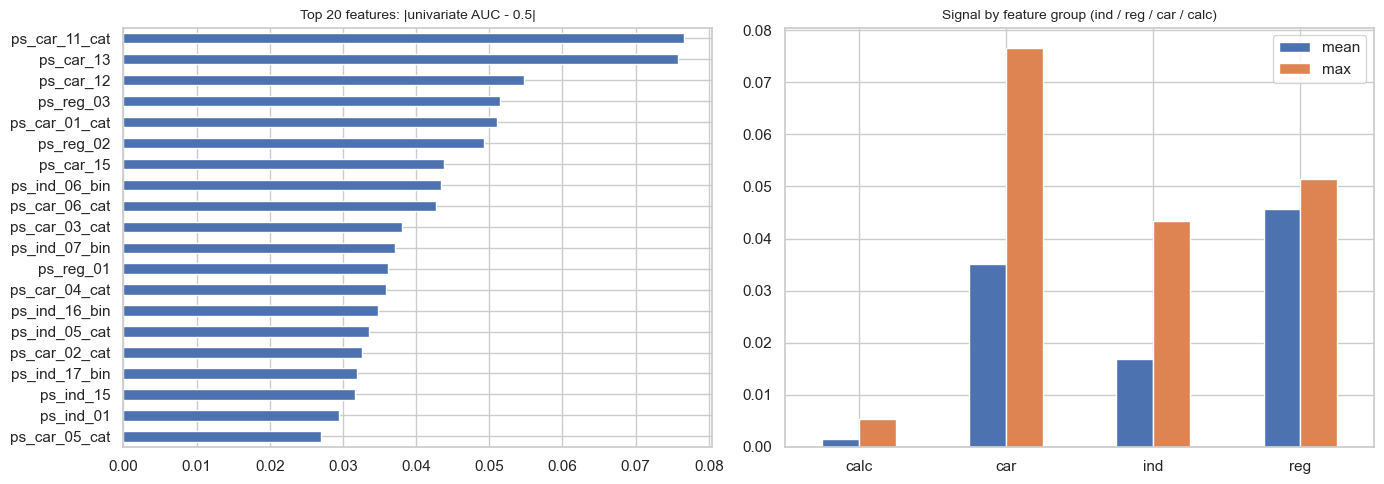

,|AUC - 0.5|
ps_car_11_cat,0.0766
ps_car_13,0.0757
ps_car_12,0.0548
ps_reg_03,0.0515
ps_car_01_cat,0.0510
ps_reg_02,0.0493
ps_car_15,0.0438
ps_ind_06_bin,0.0434
ps_car_06_cat,0.0428
ps_car_03_cat,0.0381


Strongest ps_calc_* feature: ps_calc_01 = 0.0053 | weakest 5 overall: ['ps_calc_17_bin', 'ps_ind_11_bin', 'ps_ind_10_bin', 'ps_calc_16_bin', 'ps_ind_13_bin']


In [11]:
uni = {}
for c in FEATURES:
    s = eda[c].astype(float)
    if c in cat_cols: s = s.map(eda.groupby(c)["target"].mean())
    s = s.where(s != -1).fillna(s.median()) if c not in cat_cols else s
    uni[c] = roc_auc_score(eda["target"], s)
uni = pd.Series(uni); strength = (uni - 0.5).abs().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
strength.head(20)[::-1].plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("Top 20 features: |univariate AUC - 0.5|")
cg = strength.groupby([c.split("_")[1] for c in strength.index]).agg(["mean", "max"]); cg.plot.bar(ax=ax[1]); ax[1].set_title("Signal by feature group (ind / reg / car / calc)"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
display(strength.head(10).round(4).to_frame("|AUC - 0.5|"))
calc_strength = strength[[c for c in strength.index if c.startswith("ps_calc")]]
print("Strongest ps_calc_* feature: %s = %.4f | weakest 5 overall: %s" % (calc_strength.index[0], calc_strength.iloc[0], list(strength.index[-5:])))

**Findings – which features carry signal?**
- **No single feature is strong:** the best, `ps_car_11_cat` (0.077, in-sample and therefore optimistic) and `ps_car_13` (0.076), correspond to a single-feature AUC of about 0.58. The problem is intrinsically a **weak-signal problem**; realistic model AUCs will be modest (about 0.6 – 0.65).
- By block, the mean strength is `reg` 0.045, `car` 0.035, `ind` 0.017 and **`calc` 0.002**. **All 20 `ps_calc_*` features are below 0.0053** – statistically indistinguishable from noise. Their strongest correlation with the target is 0.0035. Section 5 tests formally whether to drop them.

### 3.6 Correlation structure

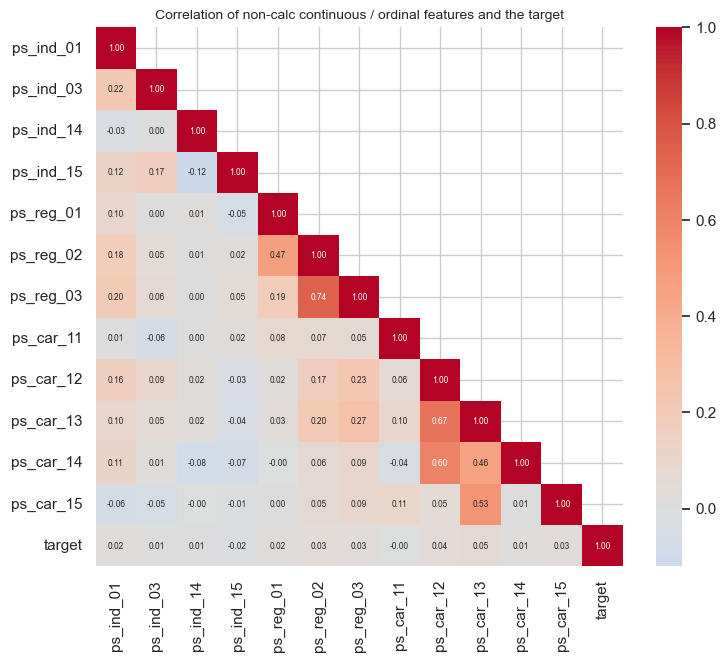

,level_0,level_1,r
20,ps_reg_03,ps_reg_02,0.744
44,ps_car_13,ps_car_12,0.672
53,ps_car_14,ps_car_12,0.603
64,ps_car_15,ps_car_13,0.530
14,ps_reg_02,ps_reg_01,0.471
54,ps_car_14,ps_car_13,0.459
42,ps_car_13,ps_reg_03,0.267
34,ps_car_12,ps_reg_03,0.232


Largest |correlation| of any ps_calc_* continuous feature with the target: 0.0035


In [12]:
cont = [c for c in num_cols if not c.startswith("ps_calc")]
tmp = eda[cont + ["target"]].where(eda[cont + ["target"]] != -1)
corr = tmp.corr()
plt.figure(figsize=(8.5, 7)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 6}, mask=np.triu(np.ones_like(corr, bool), 1))
plt.title("Correlation of non-calc continuous / ordinal features and the target"); plt.show()
pairs = corr.where(np.tril(np.ones(corr.shape), -1).astype(bool)).stack().rename("r").reset_index()
pairs = pairs[(pairs.level_0 != "target") & (pairs.level_1 != "target")]
display(pairs.reindex(pairs.r.abs().sort_values(ascending=False).index).head(8).round(3))
calc_corr = eda[[c for c in num_cols if c.startswith("ps_calc")] + ["target"]].corr()["target"].drop("target")
print("Largest |correlation| of any ps_calc_* continuous feature with the target: %.4f" % calc_corr.abs().max())

**Observations – correlations**
- The strongest relationships between non-calc features are `ps_reg_03`–`ps_reg_02` (0.74), `ps_car_13`–`ps_car_12` (0.67), `ps_car_14`–`ps_car_12` (0.60) and `ps_car_15`–`ps_car_13` (0.53): moderate redundancy inside the `reg` and `car` blocks, and **no multicollinearity problem** (all VIFs ≤ 3.4 in Section 4.1).
- **Limit of this view:** Pearson correlation only measures *linear* association between *numeric* variables; it says nothing about the 14 categorical features or non-linear effects, which is why model-based importance is used in Section 10.

### 3.7 Outliers (continuous / ordinal features) — with the actual records

In [13]:
def iqr_summary(s):
    s = s.where(s != -1).dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5 * i, q3 + 1.5 * i
    out = s[(s < lo) | (s > hi)]
    return pd.Series({"lower_fence": lo, "upper_fence": hi, "n_outliers": len(out), "pct": 100 * len(out) / len(s),
                      "claim_rate_outliers": eda.loc[out.index, "target"].mean() if len(out) else np.nan})
out_tbl = eda[cont].apply(iqr_summary).T; display(out_tbl.sort_values("pct", ascending=False).round(3))
worst = out_tbl.sort_values("pct", ascending=False).index[0]
print("Records with the most extreme values of %s:" % worst); display(eda.nlargest(5, worst)[[worst, "ps_car_13", "ps_reg_03", "ps_ind_03", "target"]])

,lower_fence,upper_fence,n_outliers,pct,claim_rate_outliers
ps_reg_02,-0.400,1.200,22145.0,6.201,0.051
ps_car_15,1.663,4.771,16519.0,4.626,0.024
ps_car_13,0.316,1.261,16074.0,4.501,0.066
ps_car_11,0.500,4.500,15694.0,4.395,0.047
ps_car_14,0.277,0.471,11150.0,3.364,0.050
ps_car_12,0.191,0.526,9245.0,2.589,0.065
ps_reg_03,-0.042,1.760,6344.0,2.170,0.054
ps_ind_14,0.000,0.000,3796.0,1.063,0.050
ps_ind_01,-4.500,7.500,0.0,0.000,NaN
ps_ind_03,-4.000,12.000,0.0,0.000,NaN


Records with the most extreme values of ps_reg_02:


,ps_reg_02,ps_car_13,ps_reg_03,ps_ind_03,target
463640,1.8,1.638244,2.149855,8,0
339972,1.8,1.357577,1.347683,7,0
589940,1.8,1.121411,1.931483,10,0
462034,1.8,1.102458,1.741946,3,0
442013,1.8,0.701077,1.275490,7,1


**Decision on outliers – retain, do not delete**
- IQR outliers are frequent only for the ordinal / skewed variables: `ps_reg_02` 6.2 %, `ps_car_15` 4.6 %, `ps_car_13` 4.5 %, `ps_car_11` 4.4 %, `ps_car_14` 3.4 %, `ps_car_12` 2.6 %, `ps_reg_03` 2.2 %, `ps_ind_14` 1.1 % (its IQR is 0, so every non-zero value is flagged). `ps_ind_01/03/15` and `ps_reg_01` have none.
- The displayed extreme records (e.g. the five largest `ps_reg_02` = 1.8) are valid values of a bounded scale, not data errors. For most variables the outliers have a **higher** claim rate than average (`ps_car_13` 6.6 %, `ps_car_12` 6.5 %, `ps_reg_02` 5.1 %, `ps_reg_03` 5.4 %), so removing them would remove signal. They are kept; tree models are insensitive to them and scaling handles the linear model.

## 4. Preprocessing & feature engineering

Only **stateless, row-wise** steps are written by hand; everything that learns from data (imputation, scaling, encoding, the model) sits inside the `Pipeline` and is fitted on training folds only.

| Issue found in the EDA | Treatment | Reason |
|---|---|---|
| `id` | removed | row label, no information (2.2) |
| `-1` in categorical columns | own category `"-1"` | missingness can carry signal (2.3) |
| `-1` in continuous columns | → `NaN`, median imputation + missing-indicator (in the pipeline) | keeps the information that the value was missing |
| 14 categorical features, one with 104 levels | one-hot; levels with < 0.5 % of rows are grouped as "infrequent"; unseen levels → infrequent | avoids thousands of near-empty dummies |
| Different scales | `StandardScaler` | needed for logistic regression, harmless for trees |
| Many missing values per row | optional count feature `n_missing` | cheap summary of data completeness |
| 17 binary features | optional count feature `ind_bin_sum` | cheap summary of the individual-flag block |
| 20 `ps_calc_*` features with ≈ no signal (3.5, 3.6) | **kept or dropped by evidence in Section 5** | parsimony vs. information |

In [14]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    # Stateless, row-wise feature construction: nothing is learned from the data, so it cannot leak.
    def __init__(self, drop_calc=False, add_counts=False):
        self.drop_calc = drop_calc
        self.add_counts = add_counts
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        cats = [c for c in X.columns if c.endswith("_cat")]
        bins = [c for c in X.columns if c.endswith("_bin")]
        nums = [c for c in X.columns if c not in cats + bins]
        if self.add_counts:
            X["n_missing"] = (X[cats + bins + nums] == -1).sum(axis=1)
            X["ind_bin_sum"] = X[[c for c in bins if c.startswith("ps_ind")]].sum(axis=1)
        X[nums] = X[nums].where(X[nums] != -1, np.nan)          # numeric -1 -> NaN
        for c in cats:
            X[c] = X[c].astype(str)                               # -1 stays as its own category
        if self.drop_calc:
            X = X.drop(columns=[c for c in X.columns if c.startswith("ps_calc")])
        return X

def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False, dtype=np.float32)
    except TypeError:                       # older scikit-learn
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

FE_KW = {}      # set after the feature-set decision in Section 5
def make_pipeline(model):
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), selector(dtype_include="number")),
        ("cat", make_ohe(), selector(dtype_exclude="number"))])
    return Pipeline([("fe", FeatureEngineer(**FE_KW)), ("prep", prep), ("clf", model)])

### 4.1 Checks on the engineered / transformed inputs

In [15]:
fe = FeatureEngineer(add_counts=True).fit_transform(X_fit.sample(60000, random_state=RS))
assert fe["n_missing"].between(0, X_fit.shape[1]).all() and fe["ind_bin_sum"].between(0, 13).all(), "impossible counts"
assert not fe.select_dtypes(exclude="number").isin(["nan", "None"]).any().any(), "NaN leaked into a categorical column"
print("Range checks passed: counts are within their possible ranges; no NaN strings in categorical columns.")
# multicollinearity of the continuous inputs (median-imputed), VIF
num_fe = fe.select_dtypes("number")[[c for c in fe.select_dtypes("number").columns if c not in bin_cols + ["n_missing", "ind_bin_sum"]]]
num_fe = num_fe.fillna(num_fe.median()); Z = (num_fe - num_fe.mean()) / num_fe.std()
vif = {c: 1 / max(1e-9, 1 - LinearRegression().fit(Z.drop(columns=c), Z[c]).score(Z.drop(columns=c), Z[c])) for c in Z.columns}
vtab = pd.DataFrame({"VIF": pd.Series(vif).round(1), "skew": num_fe.skew().round(2)}).sort_values("VIF", ascending=False); display(vtab.head(10))
print("Features with VIF > 10:", list(vtab.index[vtab.VIF > 10]))

Range checks passed: counts are within their possible ranges; no NaN strings in categorical columns.


,VIF,skew
ps_car_13,3.4,1.76
ps_car_12,2.7,1.21
ps_reg_02,2.7,1.29
ps_reg_03,2.3,1.29
ps_car_15,1.8,-2.22
ps_car_14,1.6,0.71
ps_reg_01,1.4,-0.63
ps_ind_03,1.1,0.47
ps_ind_01,1.1,0.93
ps_ind_15,1.1,-0.29


Features with VIF > 10: []


**Result:** no impossible values; all VIFs are ≤ 3.4 (largest: `ps_car_13` 3.4, `ps_reg_02` / `ps_car_12` 2.7), so there is **no multicollinearity problem** to treat, and the moderate skews (|skew| ≤ 2.2) need no transformation.

## 5. Feature-set decision (cross-validation on the tuning sample only)
Four feature sets are compared with the same default XGBoost model and the same 3 folds. **Rule, fixed in advance:** take the set with the highest mean ROC-AUC; if a set with fewer model inputs is within **0.001** of the best, prefer it (parsimony). The validation and test sets are not used.

In [16]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
cv3b = StratifiedKFold(n_splits=3, shuffle=True, random_state=2024)    # fresh folds for the final selection
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}
pos_weight = (y_fit == 0).sum() / (y_fit == 1).sum()

def cv_summary(est, cv=cv3):
    r = cross_validate(est, X_sub, y_sub, cv=cv, scoring=SCORING, n_jobs=1)
    return {"ROC-AUC mean": r["test_roc_auc"].mean(), "ROC-AUC sd": r["test_roc_auc"].std(),
            "PR-AUC mean": r["test_pr_auc"].mean(), "fit_s": r["fit_time"].mean()}

ref = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, eval_metric="logloss", n_jobs=-1, random_state=RS)
variants = {"all features": dict(drop_calc=False, add_counts=False),
            "all + count features": dict(drop_calc=False, add_counts=True),
            "without ps_calc_*": dict(drop_calc=True, add_counts=False),
            "without ps_calc_* + count features": dict(drop_calc=True, add_counts=True)}
rows = {}
for lab, kw in variants.items():
    pipe = make_pipeline(clone(ref)).set_params(**{"fe__" + k: v for k, v in kw.items()})
    n_in = pipe.named_steps["fe"].transform(X_sub.head(5)).shape[1]
    rows[lab] = dict(cv_summary(pipe), n_inputs=n_in)
feat_df = pd.DataFrame(rows).T; display(feat_df.round(4))
best_auc = feat_df["ROC-AUC mean"].max()
ok = feat_df[feat_df["ROC-AUC mean"] >= best_auc - 0.001]
CHOICE = ok["n_inputs"].astype(int).idxmin()
FE_KW = variants[CHOICE]
print(">>> chosen feature set:", CHOICE, "->", FE_KW)

,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,fit_s,n_inputs
all features,0.6180,0.0090,0.0587,5.1030,57.0
all + count features,0.6178,0.0083,0.0580,5.2921,59.0
without ps_calc_*,0.6213,0.0086,0.0594,4.6775,37.0
without ps_calc_* + count features,0.6197,0.0080,0.0596,4.6774,39.0


>>> chosen feature set: without ps_calc_* -> {'drop_calc': True, 'add_counts': False}


**Findings – feature-set decision (rule fixed in advance)**
- **Dropping the 20 `ps_calc_*` features improves the cross-validated ROC-AUC** from 0.6180 to **0.6213** (+0.0033) while removing 20 inputs – confirming the EDA: they add noise, not information.
- The two count features (`n_missing`, `ind_bin_sum`) do not help (0.6178 and 0.6197). The rule therefore selects **"without ps_calc_*"** (37 inputs, no extra features).

## 6. Evaluation framework
- **Primary selection metric: ROC-AUC** (= normalised Gini + 1)/2; it measures how well customers are *ranked* by risk and does not depend on a threshold. **PR-AUC** is reported next to it.
- Final report: precision / recall / F1 at a tuned threshold, **lift and gains by score decile**, calibration, bootstrap confidence intervals.
- **Accuracy is not a target** (96.4 % for "always no").
- Model comparison and tuning: **3-fold stratified cross-validation on the 80,000-row tuning sample** (training part only).

## 7. Model comparison (Task 1 – model building)

### 7.1 Baselines with default settings

In [17]:
baselines = {
    "Dummy (prior)":        DummyClassifier(strategy="prior"),
    "Logistic Regression":  LogisticRegression(max_iter=500, class_weight="balanced"),
    "Decision Tree":        DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight="balanced", random_state=RS),
    "Random Forest":        RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=50, max_features="sqrt",
                                                   class_weight="balanced_subsample", n_jobs=-1, random_state=RS),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RS),
    "XGBoost":              XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, eval_metric="logloss", n_jobs=-1, random_state=RS),
}
baseline_df = pd.DataFrame({n: cv_summary(make_pipeline(m)) for n, m in baselines.items()}).T.sort_values("ROC-AUC mean", ascending=False)
baseline_df["Gini mean"] = 2 * baseline_df["ROC-AUC mean"] - 1
display(baseline_df.round(4))

,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,fit_s,Gini mean
XGBoost,0.6213,0.0086,0.0594,4.6697,0.2427
Random Forest,0.6208,0.0106,0.0589,7.0917,0.2416
Logistic Regression,0.6177,0.0122,0.0593,5.4331,0.2354
HistGradientBoosting,0.6143,0.0090,0.0556,5.2170,0.2286
Decision Tree,0.5798,0.0069,0.0500,4.0383,0.1596
Dummy (prior),0.5000,0.0000,0.0365,2.9441,0.0000


**Findings – baselines (3-fold CV, tuning sample)**
- Dummy = **0.5000** ROC-AUC (Gini 0). XGBoost (**0.6213**), Random Forest (**0.6208**), Logistic Regression (**0.6177**) and HistGradientBoosting (**0.6143**) outperform the dummy baseline; their fold standard deviations are approximately **0.009–0.012**. A depth-6 Decision Tree is weaker (**0.5798**).
- Even the best default model reaches a Gini of only about **0.24**. With 57 anonymised features and a 3.6% event rate, the achievable ranking power is limited.

### 7.2 Hyper-parameter tuning – the same procedure for every serious candidate
Logistic Regression, Random Forest, HistGradientBoosting and XGBoost: `RandomizedSearchCV`, **same folds, same metric (ROC-AUC), same number of sampled configurations (6)**, on the tuning sample. The search is deliberately small (compute budget); 7.4 shows that the gains from tuning are small anyway.

In [18]:
N_ITER = 6
searches = {
 "Logistic Regression": (LogisticRegression(max_iter=500), {
        "clf__C": loguniform(1e-3, 10), "clf__class_weight": [None, "balanced"]}),
 "Random Forest": (RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RS), {
        "clf__max_depth": [6, 8, 10, 12], "clf__min_samples_leaf": [20, 50, 100, 200],
        "clf__max_features": ["sqrt", 0.3], "clf__class_weight": [None, "balanced_subsample"]}),
 "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=RS), {
        "clf__learning_rate": loguniform(0.02, 0.15), "clf__max_depth": [3, 4, 5, 6],
        "clf__max_leaf_nodes": [15, 31], "clf__min_samples_leaf": [50, 100, 300],
        "clf__l2_regularization": loguniform(1e-3, 10), "clf__max_iter": [150, 300]}),
 "XGBoost": (XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=RS), {
        "clf__n_estimators": [150, 300], "clf__learning_rate": loguniform(0.02, 0.15),
        "clf__max_depth": [3, 4, 5], "clf__min_child_weight": [1, 5, 20],
        "clf__subsample": uniform(0.7, 0.3), "clf__colsample_bytree": uniform(0.5, 0.5),
        "clf__reg_lambda": loguniform(0.1, 20), "clf__scale_pos_weight": [1, 3]}),
}
tuned = {}
for name, (est, space) in searches.items():
    rs = RandomizedSearchCV(make_pipeline(est), space, n_iter=N_ITER, scoring="roc_auc", cv=cv3, random_state=RS, n_jobs=1, refit=False)
    rs.fit(X_sub, y_sub)
    bp = {k.replace("clf__", ""): v for k, v in rs.best_params_.items()}
    tuned[name] = make_pipeline(clone(est)).set_params(**rs.best_params_)
    print("%-22s search ROC-AUC %.4f  %s" % (name, rs.best_score_, {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in bp.items()}))

Logistic Regression    search ROC-AUC 0.6218  {'C': 0.0315, 'class_weight': None}
Random Forest          search ROC-AUC 0.6222  {'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': 'balanced_subsample'}
HistGradientBoosting   search ROC-AUC 0.6198  {'l2_regularization': 0.0036, 'learning_rate': 0.036, 'max_depth': 6, 'max_iter': 150, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}
XGBoost                search ROC-AUC 0.6262  {'colsample_bytree': 0.9916, 'learning_rate': 0.0512, 'max_depth': 3, 'min_child_weight': 20, 'n_estimators': 150, 'reg_lambda': 0.2468, 'scale_pos_weight': 1, 'subsample': 0.704}


**Findings – tuning:** the search favours **simple, heavily regularised models**: XGBoost depth 3 with 150 trees, learning rate 0.05, `min_child_weight` 20 and no extra class weight; Logistic Regression with a strong L2 penalty (C = 0.03); Random Forest with large leaves (min 100 rows, depth 12). With weak signal, complexity mainly fits noise.

### 7.3 Final selection – rule fixed in advance, fresh folds
Search scores are optimistic (they were used to pick the configuration), so each tuned pipeline is re-scored with **fresh cross-validation folds**. **Rule:** the model with the highest mean ROC-AUC becomes the single final model; models within one standard deviation are listed as statistically tied. Validation and test sets play no role.

In [19]:
tuned_df = pd.DataFrame({n: cv_summary(clone(p), cv=cv3b) for n, p in tuned.items()}).T.sort_values("ROC-AUC mean", ascending=False)
tuned_df["Gini mean"] = 2 * tuned_df["ROC-AUC mean"] - 1
display(tuned_df.round(4))
FINAL_NAME = tuned_df.index[0]
best_m, best_s = tuned_df["ROC-AUC mean"].iloc[0], tuned_df["ROC-AUC sd"].iloc[0]
tied = tuned_df[tuned_df["ROC-AUC mean"] >= best_m - best_s].index.tolist()
print(">>> FINAL MODEL:", FINAL_NAME); print("Statistically tied with the best (within 1 SD):", tied)
final_est = clone(tuned[FINAL_NAME])

,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,fit_s,Gini mean
XGBoost,0.6293,0.0047,0.0626,4.1797,0.2587
Logistic Regression,0.6277,0.0022,0.0620,4.5070,0.2553
Random Forest,0.6241,0.0035,0.0600,8.2549,0.2482
HistGradientBoosting,0.6229,0.0035,0.0605,7.4442,0.2458


>>> FINAL MODEL: XGBoost
Statistically tied with the best (within 1 SD): ['XGBoost', 'Logistic Regression']


**Findings – selection (fresh folds)**
- **XGBoost has the highest mean ROC-AUC (0.6293 ± 0.0047, Gini 0.2587)** and is the single final model under the pre-defined selection rule.
- **Logistic Regression (0.6277 ± 0.0022)** is within one standard deviation of XGBoost and is therefore reported as statistically tied under the notebook's stated rule. Random Forest scores **0.6241 ± 0.0035**, and HistGradientBoosting scores **0.6229 ± 0.0035**. XGBoost is the numerical winner, but its advantage over Logistic Regression is small.

### 7.4 Did tuning help? What does complexity buy?

,default ROC-AUC,tuned ROC-AUC,change from tuning
HistGradientBoosting,0.6143,0.6229,0.0086
Logistic Regression,0.6177,0.6277,0.0100
Random Forest,0.6208,0.6241,0.0033
XGBoost,0.6213,0.6293,0.0080


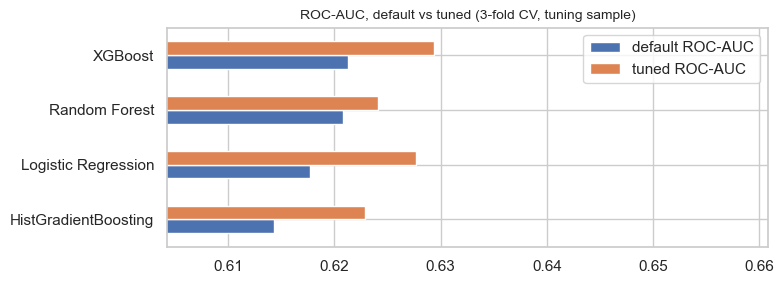

Accuracy-vs-complexity: XGBoost ROC-AUC 0.6293 vs Logistic Regression 0.6277 (gain 0.0017, Gini +0.0033); fit 4.2s vs 4.5s


In [20]:
cmp = pd.DataFrame({"default ROC-AUC": baseline_df["ROC-AUC mean"], "tuned ROC-AUC": tuned_df["ROC-AUC mean"]}).dropna()
cmp["change from tuning"] = cmp["tuned ROC-AUC"] - cmp["default ROC-AUC"]; display(cmp.round(4))
cmp[["default ROC-AUC", "tuned ROC-AUC"]].plot.barh(figsize=(8, 3)); plt.xlim(cmp[["default ROC-AUC", "tuned ROC-AUC"]].min().min() - .01, None)
plt.title("ROC-AUC, default vs tuned (3-fold CV, tuning sample)"); plt.tight_layout(); plt.show()
if FINAL_NAME != "Logistic Regression":
    lr, fin = tuned_df.loc["Logistic Regression"], tuned_df.loc[FINAL_NAME]
    print("Accuracy-vs-complexity: %s ROC-AUC %.4f vs Logistic Regression %.4f (gain %.4f, Gini +%.4f); fit %.1fs vs %.1fs"
          % (FINAL_NAME, fin["ROC-AUC mean"], lr["ROC-AUC mean"], fin["ROC-AUC mean"] - lr["ROC-AUC mean"], 2 * (fin["ROC-AUC mean"] - lr["ROC-AUC mean"]), fin["fit_s"], lr["fit_s"]))

**Findings – tuning and complexity**
- Tuning improved all four serious candidates in this run: Logistic Regression **+0.0100**, XGBoost **+0.0080**, HistGradientBoosting **+0.0086**, and Random Forest **+0.0033** ROC-AUC compared with their default baselines.
- **Accuracy-vs-complexity trade-off:** XGBoost's fresh-fold ROC-AUC is **0.6293**, compared with **0.6277** for Logistic Regression, a difference of approximately **0.0017 ROC-AUC** (about **0.0033 Gini**). The difference is small; Logistic Regression remains a defensible, simpler alternative when interpretability is a priority.

### 7.5 Learning curve – why the final model is refitted on the full training part
The tuning used 80,000 rows for speed. Here the final configuration is trained on growing parts of the training set and scored on the validation set (a diagnostic; no model choice depends on it).

,validation ROC-AUC
training rows,
10000,0.6177
40000,0.6340
80000,0.6384
160000,0.6412
357126,0.6417


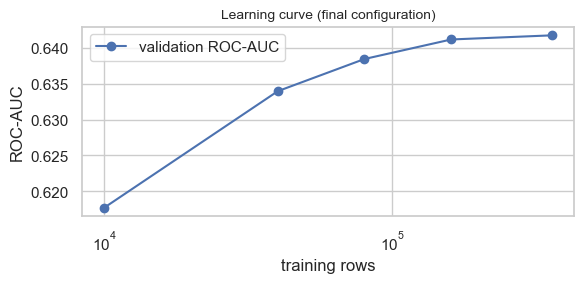

In [21]:
lc = []
for n in [10000, 40000, 80000, 160000, len(X_fit)]:
    Xs, _, ys, _ = train_test_split(X_fit, y_fit, train_size=n, stratify=y_fit, random_state=RS) if n < len(X_fit) else (X_fit, None, y_fit, None)
    m = clone(final_est).fit(Xs, ys); lc.append({"training rows": n, "validation ROC-AUC": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])})
lc = pd.DataFrame(lc).set_index("training rows"); display(lc.round(4))
lc.plot(marker="o", figsize=(6, 3)); plt.xscale("log"); plt.title("Learning curve (final configuration)"); plt.ylabel("ROC-AUC"); plt.tight_layout(); plt.show()

**Findings – learning curve:** the validation ROC-AUC rises from 0.618 (10,000 rows) to 0.634 (40,000) and 0.638 (80,000), then **flattens** (0.641 at 160,000; 0.642 with all 357,126 rows). Tuning on 80,000 rows therefore cost about 0.003 AUC at most, and the full-data refit recovers it. More rows would bring little; **better features, not more data, would be needed to improve the model.**

## 8. Final model, decision threshold and calibration data — from the validation set
The final model is fitted **once on the full training part**. Its predictions on the **validation set** (not used by any earlier step) are used to choose the threshold. The model is **not refitted afterwards**, so the threshold belongs to exactly the model that is evaluated on the test set.

Validation: ROC-AUC 0.6417 (Gini 0.2835) | PR-AUC 0.0659
F1-optimal threshold = 0.0522 -> precision 0.076 | recall 0.267 | F1 0.119 | accuracy 0.8558 (always-no: 0.9636)


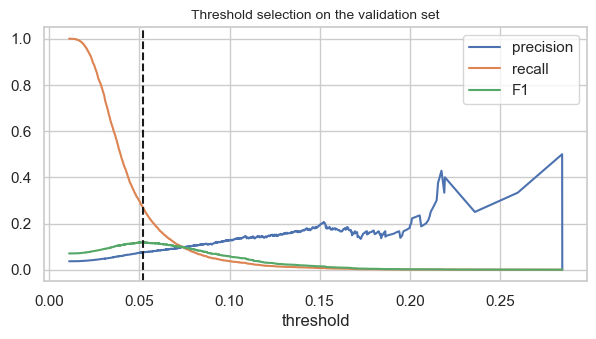

In [22]:
final_model = final_est.fit(X_fit, y_fit)
p_val = final_model.predict_proba(X_val)[:, 1]
yv = y_val.values
prec, rec, thr = precision_recall_curve(yv, p_val)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
THR = float(thr[np.argmax(f1s[:-1])])
pv = (p_val >= THR).astype(int)
print("Validation: ROC-AUC %.4f (Gini %.4f) | PR-AUC %.4f" % (roc_auc_score(yv, p_val), 2 * roc_auc_score(yv, p_val) - 1, average_precision_score(yv, p_val)))
print("F1-optimal threshold = %.4f -> precision %.3f | recall %.3f | F1 %.3f | accuracy %.4f (always-no: %.4f)"
      % (THR, precision_score(yv, pv), recall_score(yv, pv), f1_score(yv, pv), accuracy_score(yv, pv), 1 - yv.mean()))
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(thr, prec[:-1], label="precision"); ax.plot(thr, rec[:-1], label="recall"); ax.plot(thr, f1s[:-1], label="F1")
ax.axvline(THR, color="k", ls="--"); ax.set_xlabel("threshold"); ax.set_title("Threshold selection on the validation set"); ax.legend(); plt.show()

**Findings – threshold (validation set):** the F1-optimal threshold is **0.0522**. At this threshold, validation precision is **0.076 (7.6%)**, recall is **0.267 (26.7%)**, F1 is **0.119**, and accuracy is **0.8558 (85.58%)**. This is below the **0.9636 (96.36%)** accuracy of always predicting “no claim”. A single yes/no cut-off is a poor way to use a model with this much uncertainty; the ranking table below is the more useful view.

In [23]:
# More useful than a single threshold for a 3.6 % problem: what do the top x % of scores contain?  (validation set)
rows = []
for frac in [0.05, 0.10, 0.20, 0.30, 0.50]:
    k = int(len(yv) * frac); idx = np.argsort(-p_val)[:k]
    rows.append({"top share of customers": frac, "claim rate in that group": yv[idx].mean(), "lift": yv[idx].mean() / yv.mean(), "share of all claimants captured": yv[idx].sum() / yv.sum()})
display(pd.DataFrame(rows).set_index("top share of customers").round(4))

,claim rate in that group,lift,share of all claimants captured
top share of customers,,,
0.05,0.0901,2.4707,0.1235
0.10,0.0784,2.1503,0.2150
0.20,0.0669,1.8357,0.3671
0.30,0.0595,1.6325,0.4897
0.50,0.0500,1.3722,0.6861


**Reading the table (validation):** the 10 % of customers with the highest scores have a claim rate of 7.8 % (**lift 2.2 ×**) and contain 21.5 % of all claimants; the top 30 % contain 49.0 % (lift 1.6 ×). The model is a **risk-ranking tool**, not a classifier.

## 9. Final evaluation on the test set (touched once)
Only the selected model is evaluated; comparing several models on the test set would turn it into a second selection set. Confidence intervals come from a bootstrap of the test predictions (300 resamples).

### 9.1 Metrics with 95 % bootstrap intervals

,estimate,95% CI low,95% CI high
ROC-AUC,0.6393,0.6312,0.6477
Gini (2·AUC-1),0.2787,0.2625,0.2954
PR-AUC,0.0666,0.0629,0.0712
Precision,0.0746,0.0706,0.0793
Recall,0.2643,0.2518,0.2776
F1,0.1164,0.1103,0.1231
Accuracy,0.8537,0.8515,0.8557
Balanced accuracy,0.5702,0.5638,0.5771


Test claim rate = 0.0364 (PR-AUC of a random model) | 'always no' accuracy = 0.9636 | threshold = 0.0522


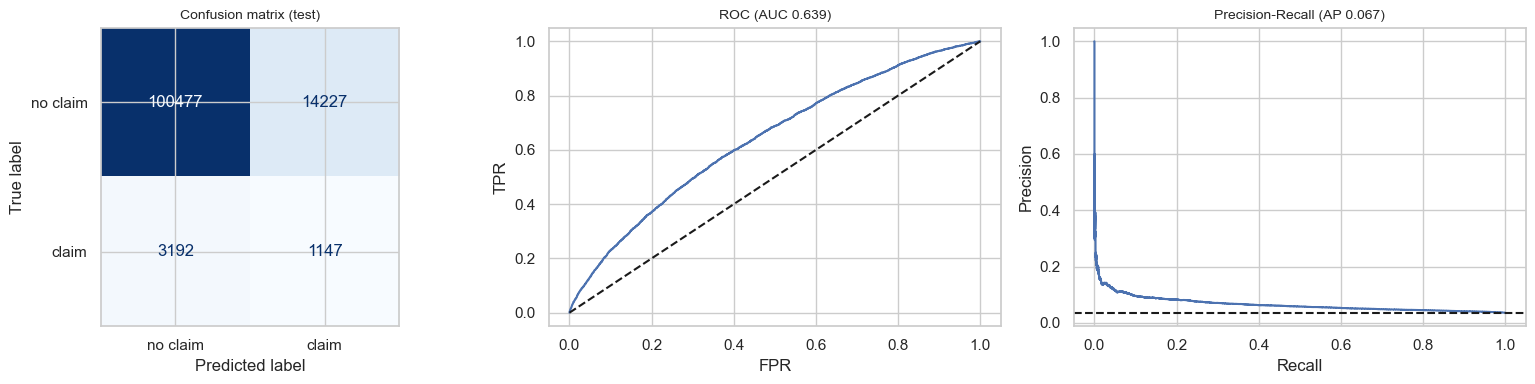

In [24]:
p_test = final_model.predict_proba(X_test)[:, 1]
yt = y_test.values; pred = (p_test >= THR).astype(int)
names = ["ROC-AUC", "Gini (2·AUC-1)", "PR-AUC", "Precision", "Recall", "F1", "Accuracy", "Balanced accuracy"]
def metric_row(y, p, q):
    a = roc_auc_score(y, p)
    return [a, 2 * a - 1, average_precision_score(y, p), precision_score(y, q, zero_division=0), recall_score(y, q), f1_score(y, q), accuracy_score(y, q), balanced_accuracy_score(y, q)]
point = metric_row(yt, p_test, pred)
rng = np.random.RandomState(RS); boots = []
for _ in range(300):
    s = rng.choice(len(yt), len(yt), replace=True); boots.append(metric_row(yt[s], p_test[s], (p_test[s] >= THR).astype(int)))
lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
res_tbl = pd.DataFrame({"estimate": point, "95% CI low": lo, "95% CI high": hi}, index=names); display(res_tbl.round(4))
print("Test claim rate = %.4f (PR-AUC of a random model) | 'always no' accuracy = %.4f | threshold = %.4f" % (yt.mean(), 1 - yt.mean(), THR))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(yt, pred, display_labels=["no claim", "claim"], cmap="Blues", ax=ax[0], colorbar=False, values_format="d"); ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(yt, p_test); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC (AUC %.3f)" % point[0]); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
pr, rc, _ = precision_recall_curve(yt, p_test); ax[2].plot(rc, pr); ax[2].axhline(yt.mean(), color="k", ls="--"); ax[2].set_title("Precision-Recall (AP %.3f)" % point[2]); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
plt.tight_layout(); plt.show()

**Findings – final test performance (selected XGBoost, test set used once)**

- **ROC-AUC 0.6393 (95% bootstrap CI 0.6312–0.6477), Gini 0.2787 (0.2625–0.2954), and PR-AUC 0.0666 (0.0629–0.0712)**. PR-AUC is about 1.83 times the test claim prevalence (0.0364), indicating useful but modest ranking signal.
- At the validation-selected F1 threshold (**0.0522**), test **precision is 0.0746 (7.46%)**, **recall is 0.2643 (26.43%)**, and **F1 is 0.1164**. In practical terms, about 7–8 out of every 100 customers flagged at this cut-off are claimants; the remaining flagged customers are false positives. This is why a single binary cutoff is not recommended as the primary business use.
- Test **accuracy is 0.8537 (85.37%)**, below the 0.9636 (96.36%) accuracy of always predicting “no claim”. Accuracy is not an appropriate headline metric for this 3.64%-prevalence problem.
- The 95% bootstrap interval for ROC-AUC is entirely above 0.5, so the model ranks better than random on this held-out sample. However, its discrimination remains moderate; the result should be described honestly rather than presented as a high-performing claims classifier.
- Cross-validation, validation and test ROC-AUC are close (approximately 0.629, 0.642 and 0.639 respectively), which is reassuring about split-to-split stability. It does not prove future-period performance; a time-based validation is still needed before deployment.


### 9.2 Ranking value: gains and lift by score decile (threshold-free)

,customers,claimants,claim_rate,lift,cum_share_of_claimants
decile,,,,,
1,11905,968,0.0813,2.2308,0.2231
2,11904,608,0.0511,1.4013,0.3632
3,11904,533,0.0448,1.2284,0.4861
4,11904,454,0.0381,1.0464,0.5907
5,11905,400,0.0336,0.9218,0.6829
6,11904,349,0.0293,0.8044,0.7633
7,11904,345,0.0290,0.7951,0.8428
8,11904,281,0.0236,0.6476,0.9076
9,11904,245,0.0206,0.5647,0.9640


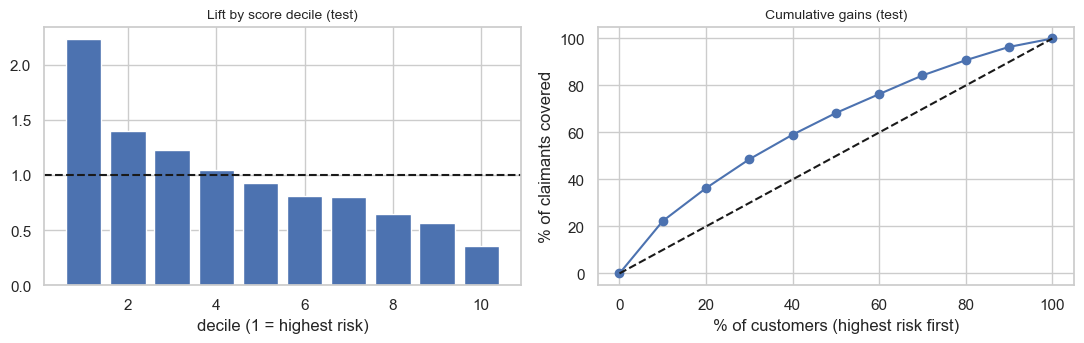

In [25]:
res = pd.DataFrame({"y": yt, "p": p_test}).sort_values("p", ascending=False).reset_index(drop=True)
res["decile"] = pd.qcut(res.index, 10, labels=range(1, 11))
dec = res.groupby("decile", observed=True).agg(customers=("y", "size"), claimants=("y", "sum"), claim_rate=("y", "mean"))
dec["lift"] = dec["claim_rate"] / yt.mean(); dec["cum_share_of_claimants"] = dec["claimants"].cumsum() / dec["claimants"].sum()
display(dec.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(dec.index.astype(int), dec["lift"], color="#4c72b0"); ax[0].axhline(1, color="k", ls="--"); ax[0].set_title("Lift by score decile (test)"); ax[0].set_xlabel("decile (1 = highest risk)")
ax[1].plot([0] + list(dec.index.astype(int) * 10), [0] + list(dec["cum_share_of_claimants"] * 100), "o-"); ax[1].plot([0, 100], [0, 100], "k--")
ax[1].set_xlabel("% of customers (highest risk first)"); ax[1].set_ylabel("% of claimants covered"); ax[1].set_title("Cumulative gains (test)")
plt.tight_layout(); plt.show()

**Findings – business view (held-out test set)**

- **Highest-risk decile:** 8.13% claim rate, **2.23× portfolio lift**, and 22.31% of all test claimants.
- **Highest-risk 30%:** the top three deciles contain **48.61% of all test claimants**.
- **Lowest-risk decile:** 1.31% claim rate and 0.36× portfolio lift. The model therefore separates risk groups, but the separation is not strong enough to make certain individual-level predictions.
- These figures support prioritisation for a controlled pilot; they do not establish that targeting a group will itself reduce claims.


### 9.3 Calibration
Isotonic calibration is **learned on the validation predictions** and applied to the test set.

Brier score  raw: 0.03475 | calibrated: 0.03475 | constant base-rate model: 0.03512
Mean predicted probability  raw: 0.0365 | calibrated: 0.0365 | observed: 0.0364


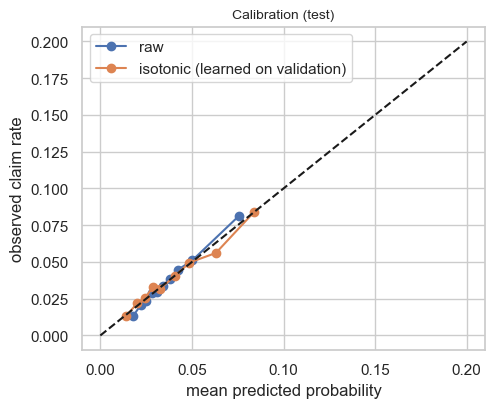

In [26]:
iso = IsotonicRegression(out_of_bounds="clip").fit(p_val, yv)
p_cal = iso.predict(p_test)
print("Brier score  raw: %.5f | calibrated: %.5f | constant base-rate model: %.5f" % (brier_score_loss(yt, p_test), brier_score_loss(yt, p_cal), brier_score_loss(yt, np.full(len(yt), y_fit.mean()))))
print("Mean predicted probability  raw: %.4f | calibrated: %.4f | observed: %.4f" % (p_test.mean(), p_cal.mean(), yt.mean()))
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for lab, p in [("raw", p_test), ("isotonic (learned on validation)", p_cal)]:
    fp_, mp_ = calibration_curve(yt, p, n_bins=10, strategy="quantile"); ax.plot(mp_, fp_, "o-", label=lab)
ax.plot([0, 0.2], [0, 0.2], "k--"); ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed claim rate"); ax.legend(); ax.set_title("Calibration (test)"); plt.show()

**Findings – calibration and deployment decision**

Calibration matters when a score is interpreted as a probability (for example, when estimating expected claim counts or allocating a fixed review budget). A model can rank customers well but still systematically over- or under-estimate their absolute probabilities. The **Brier score** is the mean squared error between predicted probabilities and binary outcomes; lower is better.

On this held-out test set, the raw model's Brier score is **0.03475**, the isotonic-calibrated score is also **0.03475**, and the constant base-rate benchmark is **0.03512**. The raw mean prediction (**0.0365**) is close to the observed claim rate (**0.0364**). Therefore, isotonic calibration provides **no measurable Brier-score improvement here**.

**Deployment recommendation:** retain the raw XGBoost probabilities as the primary scores for now. Keep the isotonic calibrator as an evaluated alternative, but only use calibrated probabilities in production if a separate future-period validation confirms improved calibration (for example, lower Brier score and a better reliability curve). The model and calibrator must be saved and versioned together if the calibrated option is deployed.


### 9.4 Subgroup checks (diagnostic only – no decision is based on them)

In [27]:
seg = X_test.copy(); seg["y"] = yt; seg["p"] = p_test; seg["pred"] = pred
seg["ps_car_03_cat missing"] = (seg["ps_car_03_cat"] == -1); seg["ps_reg_03 missing"] = (seg["ps_reg_03"] == -1)
def seg_table(col):
    g = seg.groupby(col, observed=True)
    return pd.DataFrame({"n": g.size(), "claim_rate": g["y"].mean(), "mean_score": g["p"].mean(),
                         "ROC-AUC": g.apply(lambda d: roc_auc_score(d.y, d.p) if 0 < d.y.sum() < len(d) else np.nan),
                         "recall @thr": g.apply(lambda d: recall_score(d.y, d.pred) if d.y.sum() else np.nan)}).round(4)
for c in ["ps_car_03_cat missing", "ps_reg_03 missing", "ps_ind_05_cat", "ps_ind_17_bin"]:
    print("---", c); display(seg_table(c))

--- ps_car_03_cat missing


,n,claim_rate,mean_score,ROC-AUC,recall @thr
ps_car_03_cat missing,,,,,
False,36892,0.0453,0.0440,0.6441,0.4234
True,82151,0.0325,0.0331,0.6252,0.1646


--- ps_reg_03 missing


,n,claim_rate,mean_score,ROC-AUC,recall @thr
ps_reg_03 missing,,,,,
False,97540,0.0382,0.0380,0.6327,0.2821
True,21503,0.0287,0.0293,0.6574,0.1572


--- ps_ind_05_cat


,n,claim_rate,mean_score,ROC-AUC,recall @thr
ps_ind_05_cat,,,,,
-1,1202,0.0948,0.0813,0.6061,0.7632
0,105559,0.0336,0.0340,0.6281,0.1821
1,1691,0.0526,0.0520,0.6515,0.6517
2,797,0.0878,0.0612,0.5891,0.6571
3,1642,0.0505,0.0485,0.6050,0.4819
4,3666,0.0499,0.0507,0.6338,0.5956
5,339,0.0472,0.0554,0.7310,0.7500
6,4147,0.0569,0.0558,0.6373,0.6314


--- ps_ind_17_bin


,n,claim_rate,mean_score,ROC-AUC,recall @thr
ps_ind_17_bin,,,,,
0,104600,0.0339,0.0341,0.6288,0.1905
1,14443,0.0550,0.0532,0.6421,0.5937


**Findings – subgroups (diagnostic only)**
- Ranking quality is similar across the groups with at least 1,000 customers (ROC-AUC 0.61 – 0.66); `ps_car_03_cat` missing (69 % of customers) 0.625 vs 0.644 when known.
- Recall at the threshold differs a lot: **0.59 for `ps_ind_17_bin = 1`** and 0.76 for `ps_ind_05_cat = -1` (claim rate 9.5 %, n = 1,202), but only **0.18 – 0.19 within the large default groups** (`ps_ind_17_bin = 0`, `ps_ind_05_cat = 0`). The model identifies the visible high-risk pockets and has little power inside the large "normal" majority.
- Small groups (e.g. `ps_ind_05_cat = 5`, n = 339) give unstable estimates and are not interpreted.

## 10. Model interpretation (validation set, same final model)
Permutation importance on the raw input columns with the full pipeline (30,000 validation rows, 2 repeats). Because the features are anonymised, the ranking shows *which* inputs matter, not *why*.

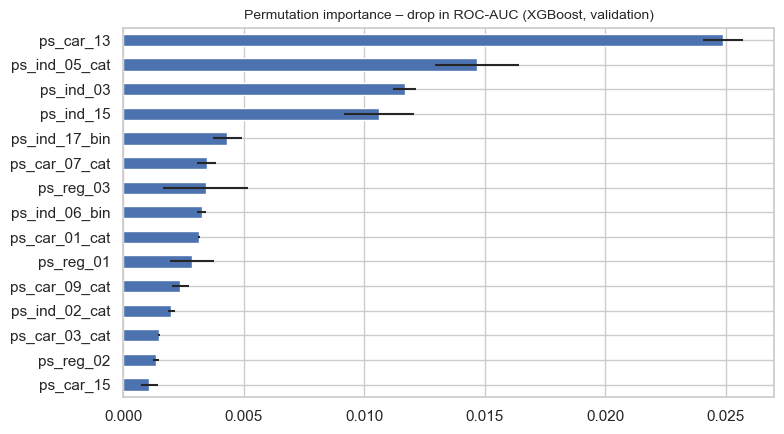

,mean,std
ps_car_13,0.0249,0.0008
ps_ind_05_cat,0.0147,0.0018
ps_ind_03,0.0117,0.0005
ps_ind_15,0.0106,0.0015
ps_ind_17_bin,0.0043,0.0006
ps_car_07_cat,0.0035,0.0004
ps_reg_03,0.0034,0.0017
ps_ind_06_bin,0.0033,0.0002
ps_car_01_cat,0.0031,0.0000
ps_reg_01,0.0028,0.0009


Total importance by feature group: {'calc': 0.0, 'car': 0.0356, 'ind': 0.0465, 'reg': 0.0076}


In [28]:
vs = X_val.sample(30000, random_state=RS); yvs = y_val.loc[vs.index]
pi = permutation_importance(final_model, vs, yvs, scoring="roc_auc", n_repeats=2, random_state=RS, n_jobs=1)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=vs.columns).sort_values("mean")
imp.tail(15).plot.barh(y="mean", xerr="std", legend=False, figsize=(8, 4.5), color="#4c72b0")
plt.title("Permutation importance – drop in ROC-AUC (%s, validation)" % FINAL_NAME); plt.tight_layout(); plt.show()
display(imp.sort_values("mean", ascending=False).head(10).round(4))
grp = imp["mean"].groupby([c.split("_")[1] for c in imp.index]).sum().round(4); print("Total importance by feature group:", grp.to_dict())

**Findings – what drives the predictions (validation set, drop in ROC-AUC)**
1. **`ps_car_13` (0.025)**, `ps_ind_05_cat` (0.015), `ps_ind_03` (0.012) and `ps_ind_15` (0.011) dominate, followed by `ps_ind_17_bin`, `ps_car_07_cat`, `ps_reg_03`, `ps_ind_06_bin`, `ps_car_01_cat` and `ps_reg_01` (0.003 – 0.004).
2. By block: `ind` 0.047, `car` 0.036, `reg` 0.008 and **`calc` exactly 0**, which confirms the decision to drop `ps_calc_*`.
3. `ps_car_11_cat`, first in the single-feature ranking, is not among the top permutation scores: its univariate score was in-sample (optimistic) and it overlaps with other car features once all are present.
4. The features are anonymised, so this says *which* inputs matter, not *why*; it is predictive, not causal.


## 11. Model comparison report & production recommendation

| Model | Default CV ROC-AUC (mean ± SD) | Tuned CV ROC-AUC (mean ± SD, fresh folds) | Tuned Gini | Tuned CV PR-AUC | Mean fit time per fold (s)* | Remarks |
|---|---:|---:|---:|---:|---:|---|
| Dummy (prior) | 0.5000 ± 0.0000 | – | 0.0000 | – | – | baseline floor |
| Logistic Regression | 0.6177 ± 0.0122 | 0.6277 ± 0.0022 | 0.2553 | 0.0620 | 2.8822 | transparent; within one SD of best |
| Decision Tree (depth 6) | 0.5798 ± 0.0069 | – | – | – | – | weakest baseline; not tuned |
| Random Forest | 0.6208 ± 0.0106 | 0.6241 ± 0.0035 | 0.2482 | 0.0600 | 8.1020 | highest mean fit time among tuned candidates in this run |
| HistGradientBoosting | 0.6143 ± 0.0090 | 0.6229 ± 0.0035 | 0.2458 | 0.0605 | 5.4717 | lowest ROC-AUC among tuned ensembles |
| **XGBoost (selected)** | **0.6213 ± 0.0086** | **0.6293 ± 0.0047** | **0.2587** | **0.0626** | **6.0099** | highest fresh-fold mean ROC-AUC by the pre-defined rule |

*Mean `fit_time` reported by `cross_validate` across the three CV folds on the 80,000-row tuning sample. These are wall-clock measurements from this notebook run and depend on hardware, software versions and system load; they are not portable benchmark times. The final XGBoost test metrics are ROC-AUC **0.6393**, Gini **0.2787** and PR-AUC **0.0666**; the test set was held out from model selection.*

**Recommended model for production evaluation: tuned XGBoost** (depth 3, 150 trees, learning rate approximately 0.05, `min_child_weight` 20, no extra class weight; 37 inputs without `ps_calc_*`), used as a **risk-ranking tool** with score tiers (deciles), not as an automatic yes/no decision.

**Honest qualifications**
1. **Logistic Regression is within one standard deviation of XGBoost** (mean ROC-AUC difference approximately 0.0017). If interpretability is a priority, it is a defensible, simpler alternative; XGBoost is selected because it has the highest mean under the rule fixed in advance.
2. Ranking power is **modest** (test Gini 0.2787; top-decile lift approximately 2.23×). The learning curve flattens, so better features are likely to help more than simply adding more rows.
3. Test accuracy (**85.37%**) is below the **96.36%** always-no baseline and must not be used as the headline measure for this imbalanced problem.

**Conditions before production:** keep `id` out of the model; retain the documented `-1` handling and feature-selection pipeline; monitor claim rate and score distribution by tier; validate on a later time period; run a fairness / regulatory review because feature meanings are anonymised; and conduct a controlled pilot before operational use.


## 12. Task 2 — Suggestions to the insurance marketing team
The score estimates the **probability that a customer files a claim** (see the note on wording at the top), so the suggestions use risk tiers. All of them are based on the held-out test set and the EDA; items marked **(pilot)** should be tested before large decisions.

| # | Suggestion | Evidence |
|---|---|---|
| 1 | **Segment customers by score decile** and manage each tier differently, instead of making yes/no decisions. | Top decile: claim rate 8.1 % (2.2 ×); bottom decile 1.3 % (0.36 ×). A single threshold gives only 7.5 % precision. |
| 2 | **Prioritise the lowest-risk 30 % for acquisition and retention offers** (discounts, cross-selling of further products). **(pilot)** | Deciles 8 – 10 have claim rates of 1.3 – 2.4 % versus 3.6 % on average and hold only 15.7 % of all claimants (the lowest 20 %, deciles 9 – 10, hold 9.2 %). |
| 3 | **Review pricing / underwriting and offer prevention programmes to the top 10 – 20 %**; do not target them with aggressive discounts. **(pilot)** | Top 10 % → 22 % of claimants; top 30 % → 49 % of claimants. |
| 4 | **Collect complete data.** 79 % of customers have at least one missing field, and some missing fields flag risk. | `ps_ind_05_cat` missing 8.3 %, `ps_car_07_cat` 7.8 %, `ps_car_09_cat` 9.1 % claim rate vs 3.6 % (small groups); `ps_car_03_cat` is missing for 69 % of customers. |
| 5 | **Ask the data owner for the meaning of the leading features** (`ps_car_13`, `ps_ind_05_cat`, `ps_ind_15`, `ps_ind_03`, `ps_car_11_cat`) and turn them into plain underwriting / marketing rules. | These dominate permutation importance; with anonymised names the model cannot yet be explained to customers or regulators. |
| 6 | **Stop producing the 20 `ps_calc_*` features** (or keep them out of scoring). | Univariate strength < 0.0053, importance exactly 0, and dropping them *improved* cross-validated ROC-AUC by 0.0033. |
| 7 | **Run a controlled pilot, then monitor.** Compare a model-tiered campaign with the current one; track claim rate per tier and retrain regularly. | Gini 0.28 with a 95 % interval of 0.26 – 0.30: real but modest, so the benefit should be measured, not assumed. |
| 8 | **Review fairness and regulation** before using scores for prices or marketing. | The anonymised features cannot be checked for proxies of sensitive attributes. |

The associations are historical and not proof of cause; a high score does not mean a customer *will* claim.



## 13. Report on challenges faced and techniques used

| # | Challenge | Evidence | Technique used | Why |
|---|---|---|---|---|
| 1 | **Strong class imbalance** | 3.64 % claims (≈ 26 : 1) | stratified splits; ROC-AUC / Gini, PR-AUC, lift and gains; threshold from a validation set; accuracy explicitly rejected | "always no" is 96.4 % accurate |
| 2 | **Anonymised features** | `ps_ind/reg/car/calc` names, no meaning | EDA by feature type and group; importance by block; recommendation to obtain definitions | meaning cannot be inferred; findings are stated as predictive only |
| 3 | **Weak signal** | best single feature ≈ 0.58 AUC; model Gini 0.28 | regularised models; confidence intervals; learning curve; honest reporting of modest lift | complexity fits noise; claims must match the evidence |
| 4 | **Missing values coded as `-1`** | 69 % / 45 % / 18 % in three columns; 79 % of rows affected | `-1` kept as a category; numeric `-1` → NaN, median imputation **plus missing-indicator**, all inside the pipeline | missingness is informative; deleting rows would remove most data |
| 5 | **High-cardinality categorical** | `ps_car_11_cat` has 104 levels | one-hot with rare levels grouped (< 0.5 %) | avoids hundreds of near-empty dummies and overfitting |
| 6 | **Useless features** | 20 `ps_calc_*` with |AUC − 0.5| < 0.0053 | rule fixed in advance, decided by cross-validation (ROC-AUC +0.0033 when dropped) | removes noise, cheaper, more stable |
| 7 | **Large data on limited compute** | 595,212 rows, single CPU | tuning on a stratified 80,000-row sample; final refit on all training rows; learning curve | a small search was feasible; the curve shows only ≈ 0.003 AUC is lost |
| 8 | **Fair model comparison** | four serious models | same folds, metric and search budget; fresh folds for selection; rule fixed in advance; ties reported | prevents tuning only a favourite or choosing on the test set |
| 9 | **Test-set discipline** | – | threshold, calibration, importance on the validation set; test used once with bootstrap CIs | keeps the headline numbers unbiased |
| 10 | **Preprocessing leakage** | – | split first; EDA on train only; stateless hand-written features; every fitted step in one `Pipeline` | validation / test rows never influence a fitted step |
| 11 | **Threshold produces poor precision** | precision 7.5 % at best F1 | use score deciles / top-share tables for decisions | a hard cut-off hides the real ranking value |
| 12 | **Calibration** | raw mean predicted probability 0.0365 vs observed claim rate 0.0364; raw and isotonic Brier scores both 0.03475 | checked calibration curve and Brier score on the held-out test set; retained raw scores because isotonic did not improve the score | probability quality is assessed separately from ranking; future-period calibration monitoring is still required |
| 13 | **Task wording vs data** | task says "buy", data describes claims | stated openly at the top; the score is treated as claim risk and the suggestions are risk-tier based | avoids a mismatch between the question and the data |
| 14 | **Statistical tie of top models** | XGBoost 0.6293 ± 0.0047 vs Logistic Regression 0.6277 ± 0.0022 | reported; Logistic Regression named as a defensible alternative | honest model choice |



## 14. Limitations and next steps
- **Weak signal:** with anonymised features the achievable Gini is about 0.28 (test 0.279, 95 % CI 0.263 – 0.295); the notebook does not claim more. Better features (driving history, vehicle details, claim history) are the realistic way to improve the model; the learning curve shows more rows of the same kind will not.
- **No time information:** the file has no date column and `id` is unrelated to the target (Section 2.2), so performance on a later period cannot be tested here. A time-based validation on newer data is therefore listed as a condition before production use.
- **Interpretation:** importance is predictive, not causal, and anonymised features cannot be audited for fairness or proxies of sensitive attributes.
- **Search budget:** 6 sampled configurations with 3-fold CV on 80,000 rows; the learning curve and the small tuning gains (+0.003 to +0.010) suggest that a larger search would not change the conclusions.
- **Model choice:** XGBoost and Logistic Regression are statistically tied; XGBoost is chosen by a rule fixed in advance, not proven superior.
- **Possible improvements:** target / frequency encoding of `ps_car_11_cat` inside the pipeline, interaction features, monotonic constraints, model blending, cost-based thresholds from real campaign costs.


## 15. Final conclusion and deployment recommendation

This project developed an end-to-end machine-learning workflow to estimate insurance claim risk (the feature names suggest motor insurance) using the supplied, highly imbalanced dataset. The analysis covered data quality, the special `-1` missing-value convention, exploratory analysis, feature engineering, feature-set comparison, cross-validated model comparison, hyperparameter tuning, threshold selection, held-out testing, calibration, subgroup diagnostics and feature importance.

The selected tuned XGBoost model achieved a **test ROC-AUC of 0.6393 (95% bootstrap CI: 0.6312–0.6477)**, **Gini of 0.2787**, and **PR-AUC of 0.0666**, compared with a test claim prevalence of 0.0364. At the threshold selected on the validation set, test precision was **7.46%**, recall was **26.43%**, and F1-score was **0.1164**. These results show that the model has real but moderate ability to rank customers by claim risk; they do not support treating its individual predictions as certain.

The business analysis is more useful when the output is treated as a **risk-ranking score**. On the held-out test set, the highest-risk 10% had an 8.13% claim rate (2.23 times the portfolio average) and contained 22.31% of all claimants. The highest-risk 30% contained 48.61% of claimants. This suggests that risk tiers could help prioritise a limited pilot for customer outreach, service support or further review. Any such pilot should measure incremental business outcomes against a control group and should not automatically be used to deny cover or make adverse customer decisions.

Isotonic calibration was fitted using validation predictions and evaluated on the test set. It did **not** improve the Brier score over the raw probabilities (both 0.03475), so the raw model probabilities are retained as the default output. Before operational use, the model should be tested on a later time period, monitored for drift and calibration, and reviewed for fairness, legal compliance and the meaning of anonymised predictors. Overall, the model is a useful proof of concept for risk segmentation, but further data and future-period validation are required before production deployment.


In [29]:
# Final step: save the fitted model, validation-fitted calibrator and model card.
# Run this cell AFTER all preceding cells have completed successfully.
# The raw XGBoost score is the recommended default because isotonic calibration
# did not improve the held-out Brier score in this experiment.
import os, json, joblib

OUTPUT_DIR = "insurance_claim_model_artifacts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(final_model, os.path.join(OUTPUT_DIR, "xgboost_claim_risk_pipeline.joblib"))
joblib.dump(iso, os.path.join(OUTPUT_DIR, "isotonic_calibrator_validation_fit.joblib"))

model_card = {
    "project": "PRCP-1010 Insurance Claim Prediction",
    "selected_model": FINAL_NAME,
    "default_probability_output": "raw XGBoost probability",
    "validation_selected_threshold": float(THR),
    "test_metrics": {
        "roc_auc": float(point[0]),
        "gini": float(point[1]),
        "pr_auc": float(point[2]),
        "precision": float(point[3]),
        "recall": float(point[4]),
        "f1": float(point[5]),
        "accuracy": float(point[6]),
        "balanced_accuracy": float(point[7])
    },
    "calibration": {
        "raw_brier_score": float(brier_score_loss(yt, p_test)),
        "isotonic_brier_score": float(brier_score_loss(yt, p_cal)),
        "decision": "Use raw probabilities by default; isotonic did not improve test Brier score."
    },
    "limitations": [
        "Moderate ranking performance and low precision at the selected threshold.",
        "Random split does not establish future-period performance.",
        "Predictor names are anonymised; fairness and business meaning require review.",
        "Not intended for automatic adverse customer or underwriting decisions."
    ]
}
with open(os.path.join(OUTPUT_DIR, "model_card.json"), "w", encoding="utf-8") as f:
    json.dump(model_card, f, indent=2)

print("Saved model artifacts:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", os.path.join(OUTPUT_DIR, filename))


Saved model artifacts:
 - insurance_claim_model_artifacts\isotonic_calibrator_validation_fit.joblib
 - insurance_claim_model_artifacts\model_card.json
 - insurance_claim_model_artifacts\xgboost_claim_risk_pipeline.joblib


### Summary of the modelling protocol
- The baseline comparison covers Dummy, Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting and XGBoost; the four serious models are then tuned with the same six-configuration randomised search and the same stratified folds, and a fresh-fold comparison selects the final model.
- The test set is held out from model selection. The threshold, the isotonic mapping and the feature-importance analysis use the training / validation partitions only.
- The last code cell (run it after all other cells) saves the fitted pipeline, the validation-fitted isotonic calibrator and a JSON model card to `insurance_claim_model_artifacts/`.
